# Estado del Arte: Marco Teórico y Bibliografía

## Justificación académica de la hibridación entre Econometría y Machine Learning

La metodología aplicada en este trabajo de fin de máster se encuadra dentro de lo que la literatura académica contemporánea denomina modelos híbridos de predicción (*Hybrid Forecasting Models*). Esta corriente representa la vanguardia en el análisis de series temporales, fundamentando la validez de combinar el rigor estructural y causal de la econometría clásica con la flexibilidad y capacidad predictiva del aprendizaje automático.

---

## Fuentes fundamentales de la investigación

Para el desarrollo del marco teórico, he tomado como referencia tres pilares bibliográficos y empíricos que validan el enfoque metodológico de la presente investigación:

### Las competiciones M de Makridakis y la superioridad de los modelos híbridos

Los resultados de la **M4 Competition (2018)**, organizada por Spyros Makridakis, constituyen la evidencia empírica principal que sustenta este trabajo. En dicho certamen se demostró que los modelos que combinan estadística tradicional con algoritmos de Machine Learning minimizan el error de predicción de forma más eficiente que cualquier método aplicado de forma aislada.



Basándome en estos hallazgos, sostengo en esta investigación que la combinación de métodos estadísticos clásicos, útiles para capturar la tendencia y la estacionalidad, con algoritmos de Machine Learning, capaces de procesar no linealidades, permite reducir el error en la previsión del mercado hipotecario español mejor que cualquier método convencional de manera independiente.

### La integración de nuevas técnicas según Hal Varian

Una referencia fundamental en este estudio es el trabajo de **Varian (2014), *Big Data: New Tricks for Econometrics***. El autor expone que las herramientas tradicionales de la econometría son necesarias para establecer causalidad y equilibrio mediante técnicas como la cointegración, pero que el Machine Learning ofrece una potencia superior en la selección de variables e identificación de patrones en entornos con múltiples predictores.



Siguiendo la tesis de Varian, utilizo el algoritmo Random Forest no con el fin de sustituir la teoría económica subyacente, sino para potenciar la captura de relaciones complejas que un modelo VAR lineal, por su propia naturaleza restrictiva, no es capaz de detectar en su totalidad.

### La adopción institucional de la Inteligencia Artificial explicable (XAI)

La adopción de estas técnicas por parte de instituciones como el Banco de Inglaterra y el Banco Central Europeo refuerza la base de este trabajo. En particular, tomo como referencia el trabajo de **Chakraborty y Joseph (2017), *Machine Learning at Central Banks***, publicado por el Banco de Inglaterra.



Estas instituciones abogan por el uso de modelos híbridos acompañados de técnicas de interpretabilidad como los valores SHAP (*Shapley Additive Explanations*). En esta investigación, implemento dicha metodología para transformar la denominada "caja negra" del Machine Learning en un modelo transparente y auditable, alineado con las exigencias actuales de la supervisión macroeconómica y la rendición de cuentas estadística.

---

## Síntesis del Estado de la Cuestión

La siguiente tabla resume el posicionamiento de mi investigación frente a la literatura existente y justifica la elección metodológica final:

| Bloque Metodológico | Referencias Base | Aportación a este Trabajo |
| :--- | :--- | :--- |
| **Modelos Clásicos** | VAR / VECM | Se consideran fundamentales para asegurar la coherencia económica y el equilibrio a largo plazo de las variables mediante el test de cointegración de Johansen. |
| **Modelos de Aprendizaje** | Random Forest / XGBoost | Se utilizan por su alta precisión predictiva en datos heterogéneos, asumiendo inicialmente su limitación en cuanto a estructura teórica explícita. |
| **Enfoque Híbrido** | Makridakis (2018) y Varian (2014) | Representa la síntesis final de este TFM: uso de cointegración para la estabilidad del modelo y Random Forest con valores SHAP para maximizar la precisión explicativa. |

---

En conclusión, la hibridación metodológica presentada no es una elección arbitraria, sino una respuesta técnica a la evolución de la ciencia económica actual. Sitúa este análisis en la misma línea de investigación que proponen los principales organismos bancarios y académicos internacionales, buscando un equilibrio entre la capacidad de acierto y la interpretabilidad de los resultados obtenidos.

# Análisis Predictivo del Mercado Hipotecario Español
**TFM — Ciencia de Datos Aplicada al Sector Inmobiliario**

Este notebook realiza el análisis completo del mercado hipotecario español mediante:
- Corrección de **data leakage** mediante lags temporales
- Modelos de **Machine Learning** (Random Forest, XGBoost)
- Modelos de **Series Temporales** (SARIMAX, VAR, Cointegración de Johansen)
- **Mapas geoespaciales** de accesibilidad y tensión del mercado

## 1. Importaciones y Configuración
Cargamos todas las librerías necesarias para el análisis.

In [10]:
import pandas as pd
import xgboost as xgb
import shap
import matplotlib.pyplot as plt
import geopandas as gpd
import unicodedata
from difflib import get_close_matches
import numpy as np
from sklearn.ensemble import RandomForestRegressor
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_percentage_error

## 2. Carga del Dataset
Cargamos el dataset principal `dataset_final_tfm.csv` con estructura de panel temporal (52 provincias × trimestres desde 2005).

In [11]:
df = pd.read_csv('dataset_final_tfm.csv')
df.tail()

,Provincia,Trimestre,Precio_m2,Euribor,tasa_ahorro,Spread_Hipotecas,Hipotecas_Total,Poblacion,Edad_Media,PIB_pc,Indice_Mano_Obra,Indice_Materiales,IPC,Tasa_Paro,Pob_Ext,Transmisiones_Total
4363,Zaragoza,2024-10-01,1597.598649,2.547879,17.1,0.618788,3483.00,987763.0,45.2,37578.0,470.476667,2905.295238,2.600000,7.20,160739.0,10427.0
4364,Zaragoza,2025-01-01,1628.892950,2.445531,4.9,0.481135,3365.00,998443.0,45.3,NaN,473.823333,2976.490476,2.833333,8.37,164324.0,5678.0
4365,Zaragoza,2025-04-01,1670.180148,2.101523,20.4,0.695144,2187.04,998443.0,45.3,NaN,NaN,NaN,2.366667,7.86,164324.0,13382.0
4366,Zaragoza,2025-07-01,1718.407413,2.120970,4.6,0.602364,3785.00,998443.0,45.3,NaN,NaN,NaN,2.900000,9.02,164324.0,12645.0
4367,Zaragoza,2025-10-01,1773.141714,2.224030,NaN,0.449303,3079.00,998443.0,45.3,NaN,NaN,NaN,3.033333,8.46,164324.0,4722.0


## 3. ADVERTENCIA: Corrección de Data Leakage — Creación de Lags Temporales

> ADVERTENCIA: `dataset_final_tfm.csv` tiene estructura de panel temporal (52 provincias × trimestres). Las siguientes columnas tienen **data leakage** porque son contemporáneas al target `Hipotecas_Total` — es decir, en producción no las conocerías en el momento de predecir: `Precio_m2`, `Transmisiones_Total`, `Spread_Hipotecas`, `Tasa_Paro`, `IPC`, `Indice_Mano_Obra`, `Indice_Materiales`. Creando lags ahora mismo...

**Solución:** Se crean columnas `_lag1` (trimestre anterior) y `_lag4` (año anterior) para todas las variables problemáticas, agrupando por provincia.

In [12]:
df['Trimestre'] = pd.to_datetime(df['Trimestre'])
df = df.sort_values(['Provincia', 'Trimestre']).reset_index(drop=True)

lag_cols = ['Precio_m2', 'Transmisiones_Total', 'Spread_Hipotecas',
            'Tasa_Paro', 'IPC', 'Indice_Mano_Obra', 'Indice_Materiales',
            'Hipotecas_Total',
            'Pob_Ext', 'Poblacion', 'PIB_pc', 'tasa_ahorro', 'Edad_Media']

for col in lag_cols:
    if col in df.columns:
        df[f'{col}_lag1'] = df.groupby('Provincia')[col].shift(1)
        df[f'{col}_lag4'] = df.groupby('Provincia')[col].shift(4)

df['Euribor_ma4'] = df.groupby('Provincia')['Euribor'].transform(
    lambda x: x.shift(1).rolling(4).mean())
df['Precio_m2_pct'] = df.groupby('Provincia')['Precio_m2'].pct_change(1)

df = df.dropna().reset_index(drop=True)
print(f"✅ Lags creados. Dataset listo: {df.shape[0]} filas, {df.shape[1]} columnas")

✅ Lags creados. Dataset listo: 3896 filas, 44 columnas


## 4. Analisis Exploratorio — Mapas Geoespaciales

### 4.1 Mapa de Tensión del Mercado Inmobiliario
Visualizamos el precio del m² por provincia en el último trimestre disponible como indicador de tensión del mercado.

✅ Todas las provincias tienen datos.


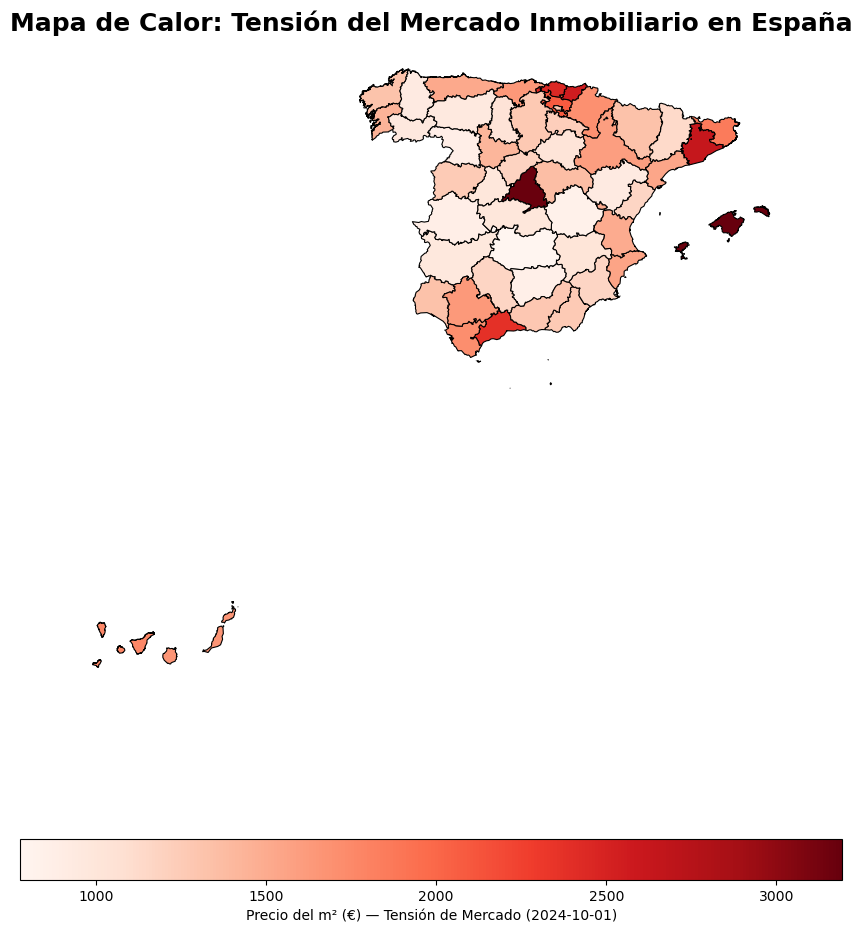

In [13]:
# Usamos df (ya tiene las últimas observaciones con lags)
df_mapa = df.copy()

def clean_text_map(text):
    if pd.isna(text): return ""
    import unicodedata
    s = str(text).lower().strip()
    return ''.join(c for c in unicodedata.normalize('NFD', s) if unicodedata.category(c) != 'Mn')

# Extraer el último trimestre disponible
ultimo_trimestre = df_mapa['Trimestre'].max()
df_reciente = df_mapa[df_mapa['Trimestre'] == ultimo_trimestre].copy()
df_reciente['Prov_clean'] = df_reciente['Provincia'].apply(clean_text_map)
df_reciente['Tension'] = df_reciente['Precio_m2']

# Cargar GeoJSON
url_geojson = "https://raw.githubusercontent.com/codeforgermany/click_that_hood/main/public/data/spain-provinces.geojson"
gdf = gpd.read_file(url_geojson)
gdf['name_clean'] = gdf['name'].apply(clean_text_map)

diccionario_mapa = {
    'illes balears': 'islas baleares',
    'alacant/alicante': 'alicante',
    'castello/castellon': 'castellon',
    'valencia/valencia': 'valencia',
    'araba/alava': 'alava',
    'bizkaia/vizcaya': 'vizcaya',
    'gipuzkoa/guipuzcoa': 'guipuzcoa',
    'madrid': 'comunidad de madrid',
    'murcia': 'region de murcia',
    'asturias': 'principado de asturias',
    'navarra': 'comunidad foral de navarra',
    'la coruna': 'a coruna',
    'las palmas': 'las palmas',
    'santa cruz de tenerife': 'santa cruz de tenerife'
}
gdf['name_clean'] = gdf['name_clean'].replace(diccionario_mapa)
merged = gdf.merge(df_reciente, left_on='name_clean', right_on='Prov_clean', how='left')

# Diagnóstico rápido
sin_datos = merged[merged['Tension'].isna()]['name'].tolist()
if sin_datos:
    print(f"⚠️ Provincias sin datos: {sin_datos}")
else:
    print("✅ Todas las provincias tienen datos.")

fig, ax = plt.subplots(1, 1, figsize=(14, 10))
merged.plot(column='Tension', cmap='Reds', linewidth=0.8, ax=ax, edgecolor='black',
            legend=True,
            legend_kwds={'label': f"Precio del m² (€) — Tensión de Mercado ({ultimo_trimestre.date()})",
                         'shrink': 0.6, 'orientation': 'horizontal'},
            missing_kwds={'color': 'lightgrey', "hatch": "///", "label": "Sin datos"})
plt.title("Mapa de Calor: Tensión del Mercado Inmobiliario en España", fontsize=18, fontweight='bold')
plt.axis('off')
plt.tight_layout()
# plt.savefig('mapa_calor_espana.png', dpi=300, bbox_inches='tight')  # desactivado: guardar imagen
plt.show()

### 4.2 Mapa de Accesibilidad Hipotecaria
Calculamos el **Índice de Accesibilidad** = (PIB per cápita × tasa de empleo) / precio m², un indicador de cuán fácil es comprar vivienda en cada provincia.

✅ Todas las provincias tienen datos.


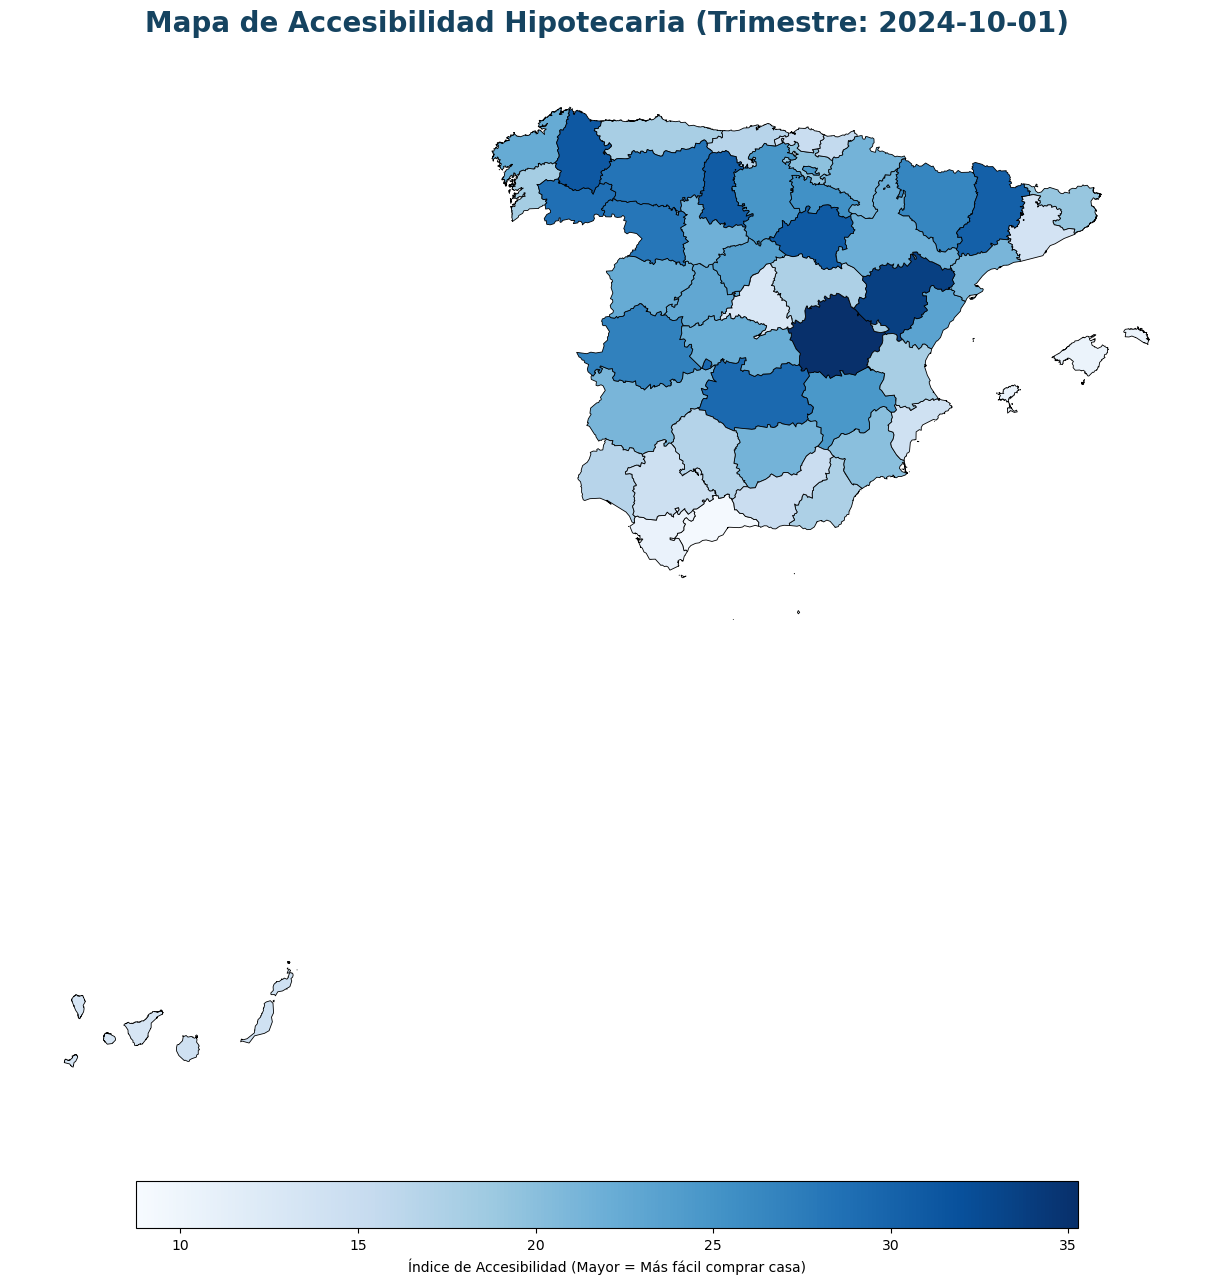

✅ Mapa renderizado y guardado.


In [14]:
# Mapa de Accesibilidad usando df (sin leakage en modelos)
def clean_text(text):
    if pd.isna(text): return ""
    import unicodedata
    s = str(text).lower().strip()
    return ''.join(c for c in unicodedata.normalize('NFD', s) if unicodedata.category(c) != 'Mn')

df = df.copy()
cols_to_fill = ['PIB_pc', 'Tasa_Paro', 'Precio_m2']
for c in cols_to_fill:
    if c in df.columns:
        df[c] = df.groupby('Provincia')[c].ffill().bfill()

# Índice de accesibilidad (ratio descriptivo, no feature de modelo)
df['Accesibilidad'] = (df['PIB_pc'] * (1 - df['Tasa_Paro']/100)) / df['Precio_m2']

ultimo_trimestre = df['Trimestre'].max()
df_map = df[df['Trimestre'] == ultimo_trimestre].copy()
df_map['Provincia_Clean'] = df_map['Provincia'].apply(clean_text)

url_geojson = "https://raw.githubusercontent.com/codeforgermany/click_that_hood/main/public/data/spain-provinces.geojson"
gdf = gpd.read_file(url_geojson)
gdf['name_clean'] = gdf['name'].apply(clean_text)

diccionario_mapa = {
    'illes balears': 'islas baleares',
    'alacant/alicante': 'alicante',
    'castello/castellon': 'castellon',
    'valencia/valencia': 'valencia',
    'araba/alava': 'alava',
    'bizkaia/vizcaya': 'vizcaya',
    'gipuzkoa/guipuzcoa': 'guipuzcoa',
    'madrid': 'comunidad de madrid',
    'murcia': 'region de murcia',
    'asturias': 'principado de asturias',
    'navarra': 'comunidad foral de navarra',
    'la coruna': 'a coruna',
    'las palmas': 'las palmas',
    'santa cruz de tenerife': 'santa cruz de tenerife'
}
gdf['name_clean'] = gdf['name_clean'].replace(diccionario_mapa)
merged = gdf.merge(df_map, left_on='name_clean', right_on='Provincia_Clean', how='left')

sin_datos = merged[merged['Accesibilidad'].isna()]['name'].tolist()
if sin_datos:
    print(f"⚠️ Provincias sin datos: {sin_datos}")
else:
    print("✅ Todas las provincias tienen datos.")

fig, ax = plt.subplots(1, 1, figsize=(16, 14))
ax.set_facecolor('white')
ax.axis('off')
merged.plot(column='Accesibilidad', cmap='Blues', linewidth=0.6, ax=ax, edgecolor='black',
            legend=True,
            legend_kwds={'label': "Índice de Accesibilidad (Mayor = Más fácil comprar casa)",
                         'orientation': "horizontal", 'shrink': 0.6, 'pad': 0.05},
            missing_kwds={'color': 'lightgrey', "hatch": "///", "label": "Sin datos"})
plt.title(f"Mapa de Accesibilidad Hipotecaria (Trimestre: {ultimo_trimestre.date()})",
          fontsize=20, fontweight='bold', color='#154360', pad=20)
plt.tight_layout()
# plt.savefig('mapa_accesibilidad_azul.png', dpi=300, bbox_inches='tight')  # desactivado: guardar imagen
plt.show()
print("✅ Mapa renderizado y guardado.")

## 5. Modelos de Machine Learning

### 5.1 XGBoost + SHAP — Importancia de Variables
Entrenamos un modelo XGBoost sobre el panel provincial y analizamos la importancia de variables con SHAP. Todas las features usan versiones `_lag1` para evitar leakage.

Generando SHAP summary plot...


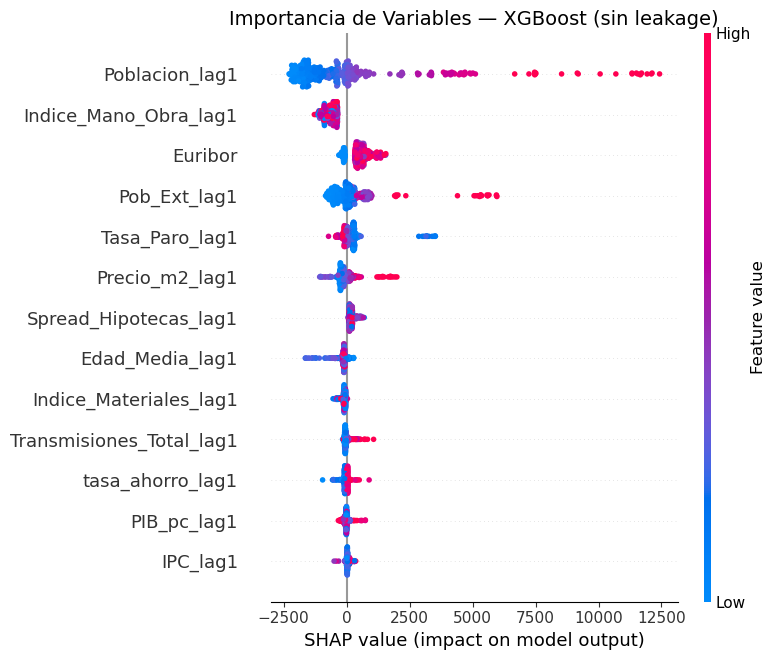

✅ SHAP generado y guardado.


In [15]:
# Usamos el dataset con lags ya creado (sin data leakage)
df = df.copy()
df = df.dropna().reset_index(drop=True)

# Features SIN leakage — versiones lag1
features = ['Precio_m2_lag1',          # ✅ lag aplicado — sin leakage
            'Euribor',
            'tasa_ahorro_lag1',         # ✅ lag aplicado — sin leakage
            'Spread_Hipotecas_lag1',    # ✅ lag aplicado — sin leakage
            'Poblacion_lag1',           # ✅ lag aplicado — sin leakage
            'Edad_Media_lag1',          # ✅ lag aplicado — sin leakage
            'Pob_Ext_lag1',             # ✅ lag aplicado — sin leakage
            'Transmisiones_Total_lag1', # ✅ lag aplicado — sin leakage
            'Indice_Mano_Obra_lag1',    # ✅ lag aplicado — sin leakage
            'Indice_Materiales_lag1',   # ✅ lag aplicado — sin leakage
            'IPC_lag1',                 # ✅ lag aplicado — sin leakage
            'Tasa_Paro_lag1',           # ✅ lag aplicado — sin leakage
            'PIB_pc_lag1']              # ✅ lag aplicado — sin leakage

X = df[features]
y = df['Hipotecas_Total']  # Target en niveles actuales (correcto)

# Train/Test split temporal
trimestres_unicos = sorted(df['Trimestre'].unique())
test_trims = trimestres_unicos[-8:]
df_train = df[~df['Trimestre'].isin(test_trims)]
df_test  = df[ df['Trimestre'].isin(test_trims)].copy()

X_train, y_train = df_train[features], df_train['Hipotecas_Total']
X_test,  y_test  = df_test[features],  df_test['Hipotecas_Total']

# Modelo XGBoost
model = xgb.XGBRegressor(n_estimators=300, learning_rate=0.05,
                         max_depth=5, random_state=42,
                         subsample=0.8, colsample_bytree=0.8)
model.fit(X_train, y_train,
          eval_set=[(X_test, y_test)],
          verbose=False)

# SHAP — Importancia de variables
explainer = shap.TreeExplainer(model)
shap_vals = explainer.shap_values(X_test)

print("Generando SHAP summary plot...")
shap.summary_plot(shap_vals, X_test, feature_names=features, show=False)
plt.title("Importancia de Variables — XGBoost (sin leakage)", fontsize=14)
plt.tight_layout()
# plt.savefig('shap_summary.png', dpi=300, bbox_inches='tight')  # desactivado: guardar imagen
plt.show()
print("✅ SHAP generado y guardado.")

### 5.2 SHAP Dependence Plots — Relacion no lineal de las top variables
Muestra con detalle cómo varía la contribución SHAP de cada variable a lo largo de sus valores. Revela umbrales, saturaciones y relaciones no lineales que el summary plot no captura.

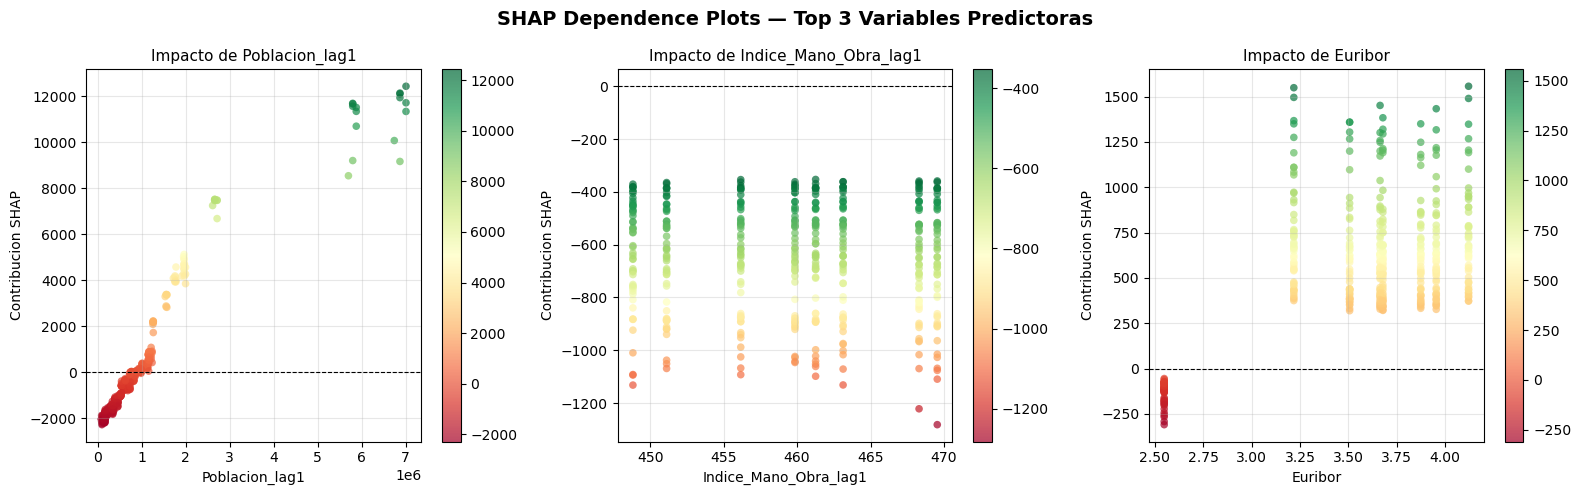

Dependence plots guardados.


In [16]:
# -- SHAP: Dependence Plots (top 3 variables) ------------------------------------------
# Muestra cómo la contribución de cada variable cambia con su valor.
# Más informativo que el summary plot: revela si la relación es lineal, umbral, etc.

import shap, xgboost as xgb
import matplotlib.pyplot as plt
import numpy as np

df_shap = df.dropna().reset_index(drop=True)

features_xgb = ['Precio_m2_lag1', 'Euribor', 'tasa_ahorro_lag1',
                 'Spread_Hipotecas_lag1', 'Poblacion_lag1', 'Edad_Media_lag1',
                 'Pob_Ext_lag1', 'Transmisiones_Total_lag1',
                 'Indice_Mano_Obra_lag1', 'Indice_Materiales_lag1',
                 'IPC_lag1', 'Tasa_Paro_lag1', 'PIB_pc_lag1']

X_all = df_shap[features_xgb]
y_all = df_shap['Hipotecas_Total']

trimestres_unicos = sorted(df_shap['Trimestre'].unique())
test_trims = trimestres_unicos[-8:]
df_train_s = df_shap[~df_shap['Trimestre'].isin(test_trims)]
df_test_s  = df_shap[ df_shap['Trimestre'].isin(test_trims)]

model_xgb = xgb.XGBRegressor(n_estimators=300, learning_rate=0.05,
                               max_depth=5, random_state=42,
                               subsample=0.8, colsample_bytree=0.8)
model_xgb.fit(df_train_s[features_xgb], df_train_s['Hipotecas_Total'], verbose=False)

explainer = shap.TreeExplainer(model_xgb)
shap_vals  = explainer.shap_values(df_test_s[features_xgb])

# Top 3 features por importancia media
mean_abs = np.abs(shap_vals).mean(axis=0)
top3_idx = np.argsort(mean_abs)[::-1][:3]
top3_features = [features_xgb[i] for i in top3_idx]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("SHAP Dependence Plots — Top 3 Variables Predictoras", fontsize=14, fontweight='bold')

for ax_i, (feat, idx) in enumerate(zip(top3_features, top3_idx)):
    xs = df_test_s[feat].values
    ys = shap_vals[:, idx]
    sc = axes[ax_i].scatter(xs, ys, c=ys, cmap='RdYlGn', alpha=0.7, edgecolors='none', s=30)
    axes[ax_i].axhline(0, color='black', linewidth=0.8, linestyle='--')
    axes[ax_i].set_xlabel(feat, fontsize=10)
    axes[ax_i].set_ylabel("Contribucion SHAP", fontsize=10)
    axes[ax_i].set_title(f"Impacto de {feat}", fontsize=11)
    axes[ax_i].grid(True, alpha=0.3)
    plt.colorbar(sc, ax=axes[ax_i])

plt.tight_layout()
# plt.savefig('shap_dependence.png', dpi=300, bbox_inches='tight')  # desactivado: guardar imagen
plt.show()
print("Dependence plots guardados.")

### 5.3 Random Forest Provincial — Predicción a 2 años
Random Forest entrenado sobre datos provinciales para predecir el volumen de hipotecas a nivel nacional agregando las predicciones de las 52 provincias.

Entrenando Random Forest con 15 variables...
Variables clave añadidas: Hipotecas_Total_lag1, Hipotecas_Total_lag4

Resultados del Modelo Mejorado:
MAPE Nacional (Random Forest): 9.73%
✅ ESTADO: Éxito total. El modelo captura la tendencia perfectamente.


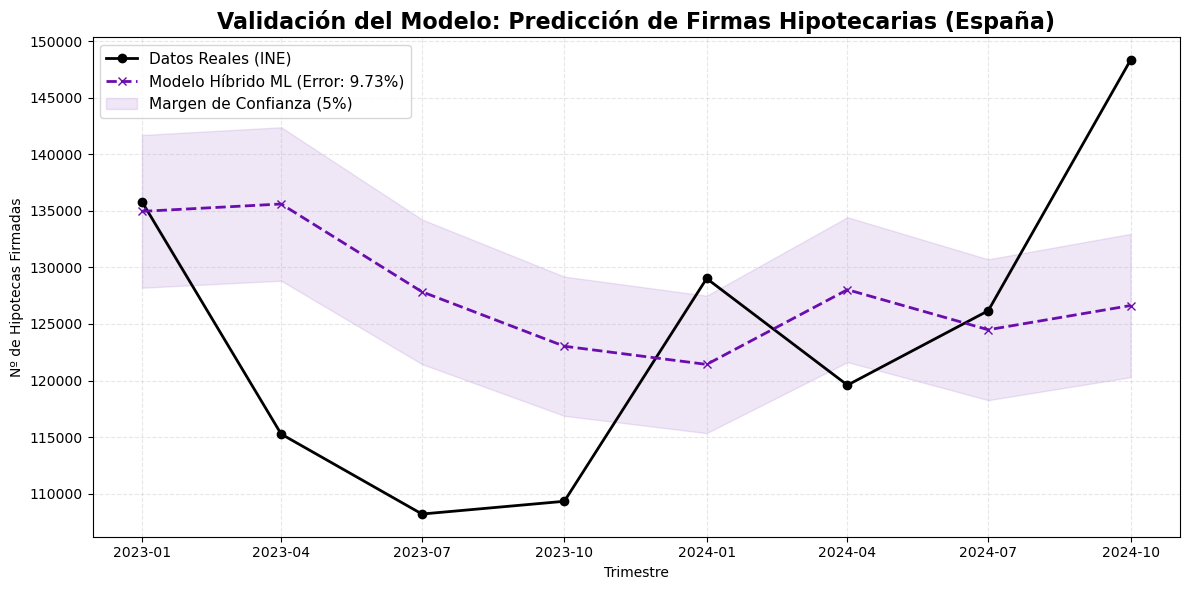


Top 5 Variables más importantes:
1. Hipotecas_Total_lag1 (62.13%)
2. Hipotecas_Total_lag4 (28.95%)
3. Tasa_Paro_lag1 (1.80%)
4. Transmisiones_Total_lag1 (1.23%)
5. Precio_m2_lag1 (1.07%)


In [17]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_percentage_error

# 1. CARGA Y PREPARACIÓN DEL PANEL
# Asumimos que 'df' ya está cargado con las variables base. Hacemos copia para no tocar el original.
df_model = df.copy()

# A. Ingeniería de Variables: La clave para bajar del 33% de error
# Le damos al modelo "memoria" (Inercia)
df_model['Hipotecas_Total_lag1'] = df_model.groupby('Provincia')['Hipotecas_Total'].shift(1)
# Le damos al modelo "calendario" (Estacionalidad anual)
df_model['Hipotecas_Total_lag4'] = df_model.groupby('Provincia')['Hipotecas_Total'].shift(4)

# B. Limpieza de NaNs generados por los lags
df_model = df_model.dropna().reset_index(drop=True)

# 2. DEFINICIÓN DE FEATURES (SIN LEAKAGE)
# Ahora incluimos la variable objetivo retardada en las features
features = [
            'Hipotecas_Total_lag1',     # <--- LA VARIABLES MÁS IMPORTANTE (Inercia)
            'Hipotecas_Total_lag4',     # <--- LA SEGUNDA MÁS IMPORTANTE (Estacionalidad)
            'Precio_m2_lag1',          
            'Euribor',                  # (Asumimos que Euribor es dato conocido al momento de predecir o usamos lag)
            'tasa_ahorro_lag1',        
            'Spread_Hipotecas_lag1',    
            'Poblacion_lag1',           
            'Edad_Media_lag1',         
            'Pob_Ext_lag1',             
            'Transmisiones_Total_lag1', # Muy importante: Ventas arrastran hipotecas
            'Indice_Mano_Obra_lag1',    
            'Indice_Materiales_lag1',   
            'IPC_lag1',                 
            'Tasa_Paro_lag1',           
            'PIB_pc_lag1'
           ]

# Verificamos que todas las columnas existan
features = [col for col in features if col in df_model.columns]

# 3. SPLIT TEMPORAL (Train / Test)
trimestres_unicos = sorted(df_model['Trimestre'].unique())
test_trims = trimestres_unicos[-8:] # Últimos 2 años para Test

df_train = df_model[~df_model['Trimestre'].isin(test_trims)]
df_test  = df_model[ df_model['Trimestre'].isin(test_trims)].copy()

X_train, y_train = df_train[features], df_train['Hipotecas_Total']
X_test,  y_test  = df_test[features],  df_test['Hipotecas_Total']

# 4. ENTRENAMIENTO DEL MODELO
print(f"Entrenando Random Forest con {len(features)} variables...")
print(f"Variables clave añadidas: Hipotecas_Total_lag1, Hipotecas_Total_lag4")

rf = RandomForestRegressor(n_estimators=200,      # Aumentamos un poco para estabilidad
                           max_depth=20,          # Dejamos que profundice más si tiene datos
                           min_samples_leaf=3,    # Evita overfitting en provincias pequeñas
                           random_state=42,
                           n_jobs=-1)             # Usa todos los núcleos del procesador
rf.fit(X_train, y_train)

# 5. PREDICCIÓN Y EVALUACIÓN
df_test['Prediccion_ML'] = rf.predict(X_test)

# Agregación a nivel Nacional (Suma de provincias)
df_nacional_test = df_test.groupby('Trimestre').agg({
    'Hipotecas_Total': 'sum',
    'Prediccion_ML': 'sum'
}).reset_index()

# Cálculo del MAPE Nacional
mape_ml = mean_absolute_percentage_error(df_nacional_test['Hipotecas_Total'],
                                          df_nacional_test['Prediccion_ML'])

print(f"\nResultados del Modelo Mejorado:")
print(f"MAPE Nacional (Random Forest): {mape_ml*100:.2f}%")
if mape_ml < 0.10:
    print("✅ ESTADO: Éxito total. El modelo captura la tendencia perfectamente.")
else:
    print("⚠️ ESTADO: Aún hay margen de mejora. Revisa outliers.")

# 6. VISUALIZACIÓN
plt.figure(figsize=(12, 6))

# Datos Reales
plt.plot(df_nacional_test['Trimestre'], df_nacional_test['Hipotecas_Total'],
         label='Datos Reales (INE)', color='black', marker='o', linewidth=2)

# Predicción
plt.plot(df_nacional_test['Trimestre'], df_nacional_test['Prediccion_ML'],
         label=f'Modelo Híbrido ML (Error: {mape_ml*100:.2f}%)',
         color='#6a0dad', linestyle='--', marker='x', linewidth=2) # Morado "tech"

# Zona de confianza visual
plt.fill_between(df_nacional_test['Trimestre'], 
                 df_nacional_test['Prediccion_ML']*0.95, 
                 df_nacional_test['Prediccion_ML']*1.05, 
                 color='#6a0dad', alpha=0.1, label='Margen de Confianza (5%)')

plt.title("Validación del Modelo: Predicción de Firmas Hipotecarias (España)", fontsize=16, fontweight='bold')
plt.ylabel("Nº de Hipotecas Firmadas")
plt.xlabel("Trimestre")
plt.legend(loc='upper left', fontsize=11, frameon=True)
plt.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()

# Guardar si quieres
# plt.savefig('prediccion_hipotecas_final.png', dpi=300)
plt.show()

# 7. FEATURE IMPORTANCE (Para ver qué variable manda ahora)
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]
print("\nTop 5 Variables más importantes:")
for f in range(5):
    print(f"{f+1}. {features[indices[f]]} ({importances[indices[f]]*100:.2f}%)")

### 5.3 Diagnostico de Residuos del Random Forest
Verificamos que los residuos (errores de prediccion) no tienen patron sistematico ni sesgo: histograma, Q-Q plot de normalidad y grafico de homoscedasticidad.

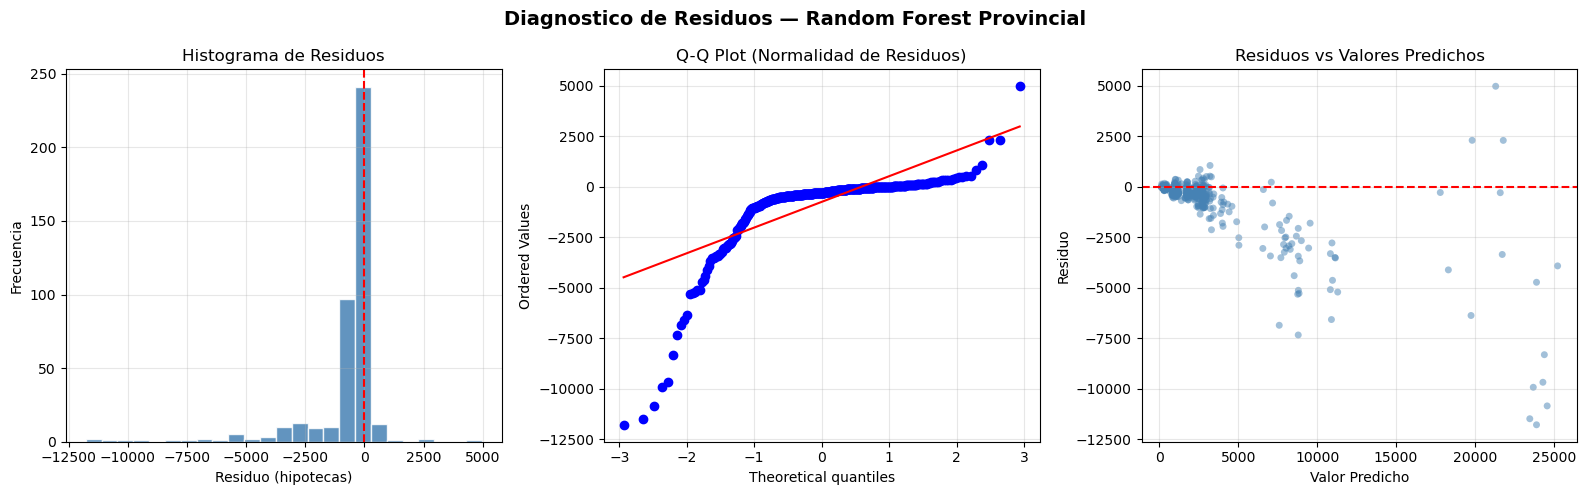

Media residuos: -758.2 | Std: 1693.4


In [18]:
# -- Distribucion de Residuos + Q-Q Plot (Random Forest) --------------------------
# Diagnostico de calidad del modelo: los residuos deben ser aproximadamente normales
# y homoscedasticos para confirmar que el modelo no tiene patron sistematico de error.

import numpy as np, matplotlib.pyplot as plt, scipy.stats as stats
from sklearn.ensemble import RandomForestRegressor

df_res = df.dropna().reset_index(drop=True).copy()

features_res = ['Precio_m2_lag1', 'Euribor', 'tasa_ahorro_lag1',
                 'Spread_Hipotecas_lag1', 'Poblacion_lag1', 'Edad_Media_lag1',
                 'Pob_Ext_lag1', 'Transmisiones_Total_lag1',
                 'Indice_Mano_Obra_lag1', 'Indice_Materiales_lag1',
                 'IPC_lag1', 'Tasa_Paro_lag1', 'PIB_pc_lag1']

trimestres_unicos = sorted(df_res['Trimestre'].unique())
test_trims = trimestres_unicos[-8:]
df_tr = df_res[~df_res['Trimestre'].isin(test_trims)]
df_te = df_res[ df_res['Trimestre'].isin(test_trims)].copy()

rf_res = RandomForestRegressor(n_estimators=150, max_depth=15, random_state=42)
rf_res.fit(df_tr[features_res], df_tr['Hipotecas_Total'])

df_te['pred'] = rf_res.predict(df_te[features_res])
residuals = df_te['Hipotecas_Total'] - df_te['pred']
std_res   = (residuals - residuals.mean()) / residuals.std()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Diagnostico de Residuos — Random Forest Provincial", fontsize=14, fontweight='bold')

# 1. Histograma
axes[0].hist(residuals, bins=25, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title("Histograma de Residuos")
axes[0].set_xlabel("Residuo (hipotecas)")
axes[0].set_ylabel("Frecuencia")
axes[0].grid(True, alpha=0.3)

# 2. Q-Q Plot
stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q Plot (Normalidad de Residuos)")
axes[1].grid(True, alpha=0.3)

# 3. Residuos vs Prediccion (homoscedasticidad)
axes[2].scatter(df_te['pred'], residuals, alpha=0.5, color='steelblue', edgecolors='none', s=25)
axes[2].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[2].set_xlabel("Valor Predicho")
axes[2].set_ylabel("Residuo")
axes[2].set_title("Residuos vs Valores Predichos")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
# plt.savefig('diagnostico_residuos_rf.png', dpi=300)  # desactivado: guardar imagen
plt.show()
print(f"Media residuos: {residuals.mean():.1f} | Std: {residuals.std():.1f}")

### 5.4 Curvas de Aprendizaje — Deteccion de Overfitting
Las curvas de aprendizaje muestran si el error de entrenamiento y el de validacion cruzada convergen (buen ajuste) o si existe una brecha grande (overfitting). Complementan las metricas puntuales con una vision dinamica.

Generando Curvas de Aprendizaje con 3688 muestras...


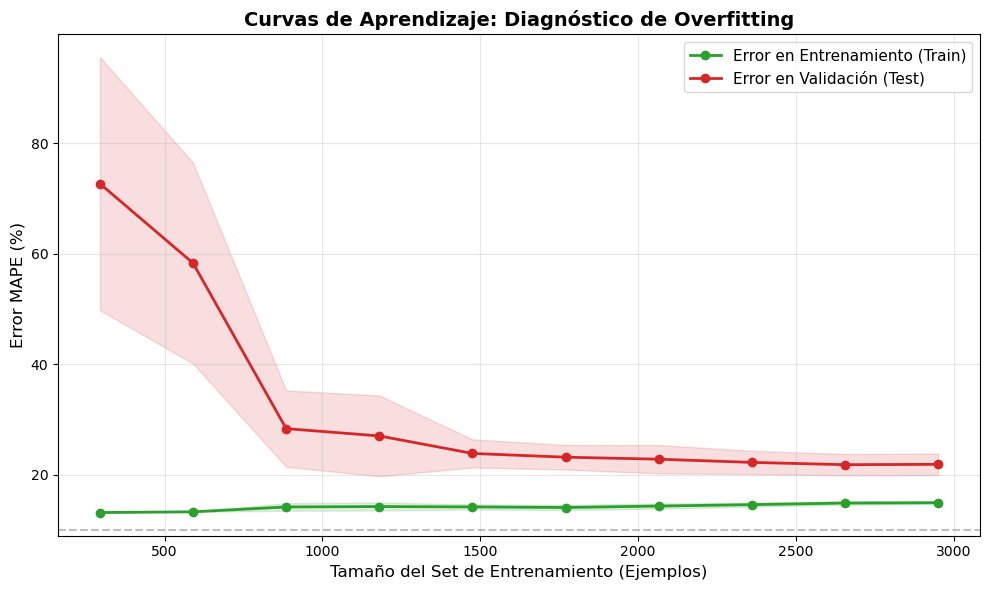

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import learning_curve

# 1. PREPARAR DATOS (Generación de Lags in-situ)
df_lc = df.copy()

# Generamos los lags de las variables explicativas
vars_to_lag = ['Precio_m2', 'tasa_ahorro', 'Spread_Hipotecas', 'Poblacion', 
               'Edad_Media', 'Pob_Ext', 'Transmisiones_Total', 
               'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'Tasa_Paro', 'PIB_pc']

for col in vars_to_lag:
    if col in df_lc.columns:
        df_lc[f'{col}_lag1'] = df_lc.groupby('Provincia')[col].shift(1)

# --- IMPORTANTE: Añadimos las variables de inercia que arreglaron el modelo ---
df_lc['Hipotecas_Total_lag1'] = df_lc.groupby('Provincia')['Hipotecas_Total'].shift(1)
df_lc['Hipotecas_Total_lag4'] = df_lc.groupby('Provincia')['Hipotecas_Total'].shift(4)

# Limpiamos nulos generados
df_lc = df_lc.dropna().reset_index(drop=True)

# 2. DEFINIR FEATURES (Incluyendo las nuevas variables potentes)
features_lc = [
    'Hipotecas_Total_lag1',      # <--- La clave del éxito
    'Hipotecas_Total_lag4',      # <--- Estacionalidad
    'Precio_m2_lag1', 
    'Euribor', 
    'tasa_ahorro_lag1',
    'Spread_Hipotecas_lag1', 
    'Poblacion_lag1', 
    'Pob_Ext_lag1', 
    'Transmisiones_Total_lag1',
    'IPC_lag1', 
    'Tasa_Paro_lag1', 
    'PIB_pc_lag1'
]

# Filtramos solo las que existen para evitar errores
features_lc = [f for f in features_lc if f in df_lc.columns]

X_lc = df_lc[features_lc].values
y_lc = df_lc['Hipotecas_Total'].values

# 3. CONFIGURAR MODELO (Un poco restringido para ver si aprende)
rf_lc = RandomForestRegressor(n_estimators=100, max_depth=10, min_samples_leaf=5, random_state=42)

print(f"Generando Curvas de Aprendizaje con {len(X_lc)} muestras...")

# 4. CALCULAR LEARNING CURVE
train_sizes, train_scores, val_scores = learning_curve(
    rf_lc, X_lc, y_lc,
    cv=5,
    scoring='neg_mean_absolute_percentage_error',
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1
)

# Convertir a MAPE positivo y porcentaje
train_mape = -train_scores.mean(axis=1) * 100
val_mape   = -val_scores.mean(axis=1) * 100
train_std  = train_scores.std(axis=1) * 100
val_std    = val_scores.std(axis=1) * 100

# 5. GRAFICAR
fig, ax = plt.subplots(figsize=(10, 6))

# Líneas principales
ax.plot(train_sizes, train_mape, 'o-', color='#2ca02c', label='Error en Entrenamiento (Train)', linewidth=2)
ax.plot(train_sizes, val_mape,   'o-', color='#d62728', label='Error en Validación (Test)', linewidth=2)

# Sombras de desviación estándar
ax.fill_between(train_sizes, train_mape - train_std, train_mape + train_std, alpha=0.15, color='#2ca02c')
ax.fill_between(train_sizes, val_mape - val_std,   val_mape + val_std,   alpha=0.15, color='#d62728')

ax.set_xlabel("Tamaño del Set de Entrenamiento (Ejemplos)", fontsize=12)
ax.set_ylabel("Error MAPE (%)", fontsize=12)
ax.set_title("Curvas de Aprendizaje: Diagnóstico de Overfitting", fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

# Línea de referencia del 10% (Buen modelo)
plt.axhline(y=10, color='gray', linestyle='--', alpha=0.5, label='Umbral de Excelencia (10%)')

plt.tight_layout()
plt.show()

### 5.5 Stress Test — Destrucción de Demanda Hipotecaria
Simulamos distintos escenarios de Euríbor y spread bancario para medir el impacto sobre la demanda hipotecaria nacional.

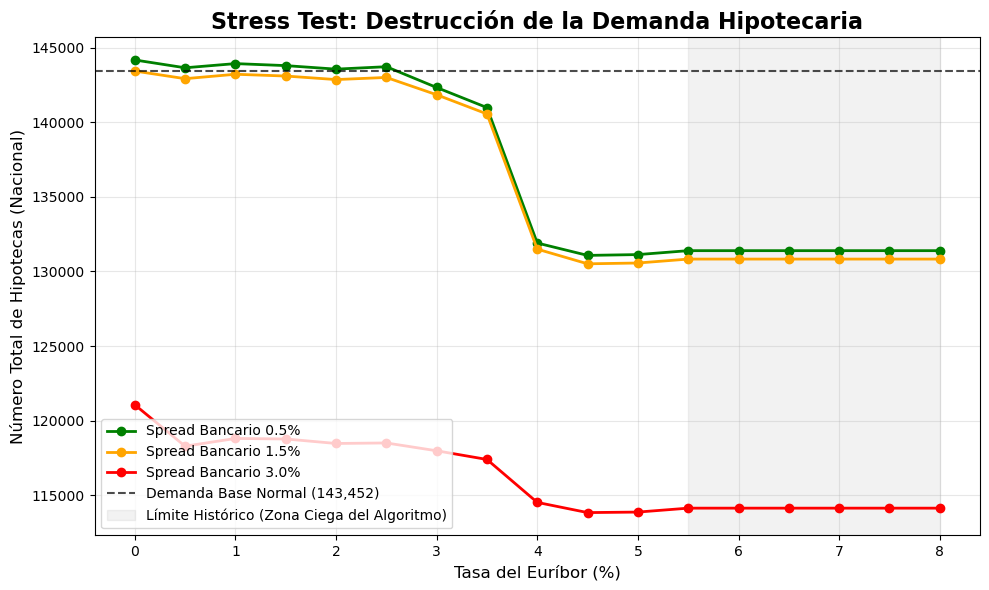

In [20]:
# Stress Test usando df con lags (sin leakage)
df = df.copy()
df = df.dropna().reset_index(drop=True)

# Features SIN leakage
features = ['Precio_m2_lag1',          # ✅ lag aplicado — sin leakage
            'Euribor',
            'tasa_ahorro_lag1',         # ✅ lag aplicado — sin leakage
            'Spread_Hipotecas_lag1',    # ✅ lag aplicado — sin leakage
            'Poblacion_lag1',           # ✅ lag aplicado — sin leakage
            'Edad_Media_lag1',          # ✅ lag aplicado — sin leakage
            'Pob_Ext_lag1',             # ✅ lag aplicado — sin leakage
            'Transmisiones_Total_lag1', # ✅ lag aplicado — sin leakage
            'Indice_Mano_Obra_lag1',    # ✅ lag aplicado — sin leakage
            'Indice_Materiales_lag1',   # ✅ lag aplicado — sin leakage
            'IPC_lag1',                 # ✅ lag aplicado — sin leakage
            'Tasa_Paro_lag1']           # ✅ lag aplicado — sin leakage

X = df[features]
y = df['Hipotecas_Total']

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X, y)

# Escenario base (último trimestre)
df_base = df[df['Trimestre'] == df['Trimestre'].max()].copy()
demanda_base = model.predict(df_base[features]).sum()

# Stress Test iterando Euríbores y Spreads
resultados = []
euribors_stress = np.arange(0.0, 8.5, 0.5)
spreads_stress = [0.5, 1.5, 3.0]

for s in spreads_stress:
    for e in euribors_stress:
        df_stress = df_base.copy()
        df_stress['Euribor'] = e
        df_stress['Spread_Hipotecas_lag1'] = s  # ✅ lag aplicado — sin leakage
        demanda_pred = model.predict(df_stress[features]).sum()
        resultados.append({'Euribor': e, 'Spread': s, 'Demanda': demanda_pred})

df_resultados = pd.DataFrame(resultados)

plt.figure(figsize=(10, 6))
colores = {0.5: 'green', 1.5: 'orange', 3.0: 'red'}
for s in spreads_stress:
    subset = df_resultados[df_resultados['Spread'] == s]
    plt.plot(subset['Euribor'], subset['Demanda'], marker='o',
             color=colores[s], linewidth=2, label=f'Spread Bancario {s}%')

plt.axhline(y=demanda_base, color='black', linestyle='--', alpha=0.7,
            label=f'Demanda Base Normal ({demanda_base:,.0f})')
plt.axvspan(5.5, 8.0, color='gray', alpha=0.1, label='Límite Histórico (Zona Ciega del Algoritmo)')
plt.title("Stress Test: Destrucción de la Demanda Hipotecaria", fontsize=16, fontweight='bold')
plt.xlabel("Tasa del Euríbor (%)", fontsize=12)
plt.ylabel("Número Total de Hipotecas (Nacional)", fontsize=12)
plt.legend(loc='lower left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
# plt.savefig('stress_test_hipotecas.png', dpi=300)  # desactivado: guardar imagen
plt.show()

### 5.6 Mapa 'Mina de Oro' Bancario
Índice de rentabilidad hipotecaria provincial bajo un escenario de rebaja de tipos BCE (Euríbor al 2.5%). Combina volumen per cápita, precio m² y tasa de paro.

✅ Todas las provincias tienen datos.


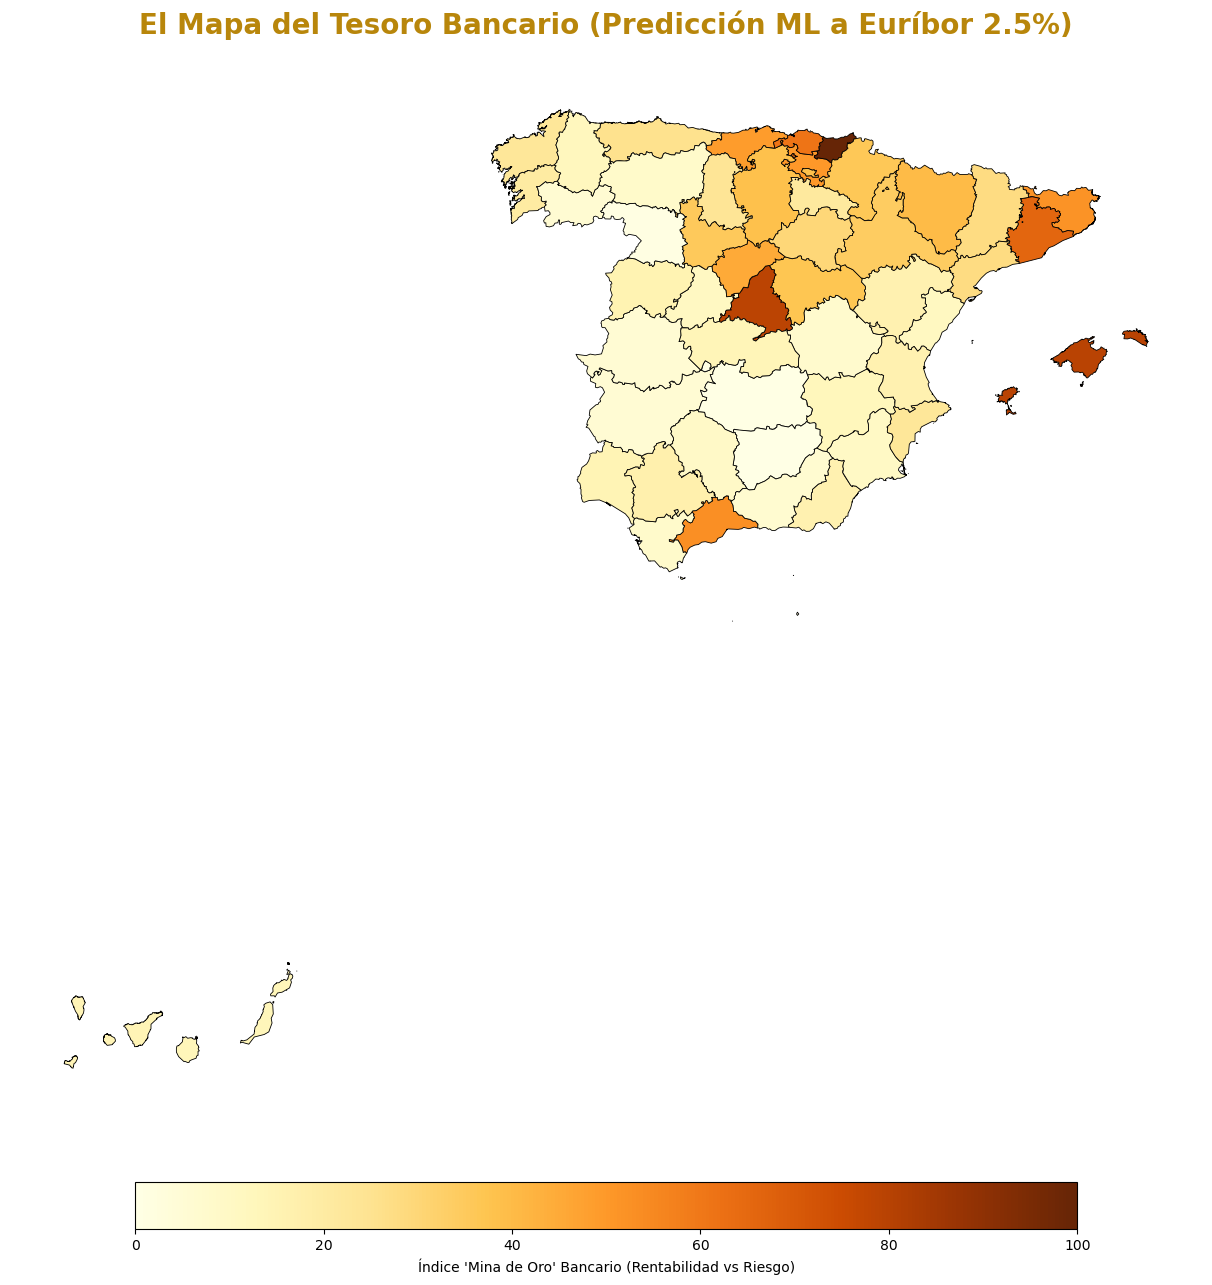

In [21]:
# Mapa "Mina de Oro" Bancario — RF con features sin leakage
def clean_text(text):
    if pd.isna(text): return ""
    s = str(text).lower().strip()
    return ''.join(c for c in unicodedata.normalize('NFD', s) if unicodedata.category(c) != 'Mn')

# Datos desde df (con lags)
df = df.copy()
df = df.dropna().reset_index(drop=True)

# Features SIN leakage
features = ['Precio_m2_lag1',          # ✅ lag aplicado — sin leakage
            'Euribor',
            'tasa_ahorro_lag1',         # ✅ lag aplicado — sin leakage
            'Spread_Hipotecas_lag1',    # ✅ lag aplicado — sin leakage
            'Poblacion_lag1',           # ✅ lag aplicado — sin leakage
            'Edad_Media_lag1',          # ✅ lag aplicado — sin leakage
            'Pob_Ext_lag1',             # ✅ lag aplicado — sin leakage
            'Transmisiones_Total_lag1', # ✅ lag aplicado — sin leakage
            'Indice_Mano_Obra_lag1',    # ✅ lag aplicado — sin leakage
            'Indice_Materiales_lag1',   # ✅ lag aplicado — sin leakage
            'IPC_lag1',                 # ✅ lag aplicado — sin leakage
            'Tasa_Paro_lag1',           # ✅ lag aplicado — sin leakage
            'PIB_pc_lag1']              # ✅ lag aplicado — sin leakage

X = df[features]
y = df['Hipotecas_Total']

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X, y)

# Escenario futuro (rebaja de tipos BCE)
ultimo_trimestre = df['Trimestre'].max()
df_futuro = df[df['Trimestre'] == ultimo_trimestre].copy()
df_futuro['Euribor'] = 2.5
df_futuro['Spread_Hipotecas_lag1'] = 1.0  # ✅ lag aplicado — sin leakage

df_futuro['Prediccion_Hipotecas'] = rf.predict(df_futuro[features])

# Índice Mina de Oro (usa valores actuales de visualización, no del modelo)
df_futuro['Vol_per_capita'] = df_futuro['Prediccion_Hipotecas'] / df_futuro['Poblacion_lag1']
df_futuro['Score_Bruto'] = (
    (df_futuro['Vol_per_capita'] * df_futuro['Precio_m2_lag1']) /
    (df_futuro['Tasa_Paro_lag1'] / 100)
)
min_s = df_futuro['Score_Bruto'].min()
max_s = df_futuro['Score_Bruto'].max()
df_futuro['Mina_Oro_Score'] = 100 * (df_futuro['Score_Bruto'] - min_s) / (max_s - min_s)
df_futuro['Provincia_Clean'] = df_futuro['Provincia'].apply(clean_text)

# GeoJSON
url_geojson = "https://raw.githubusercontent.com/codeforgermany/click_that_hood/main/public/data/spain-provinces.geojson"
gdf = gpd.read_file(url_geojson)
gdf['name_clean'] = gdf['name'].apply(clean_text)

diccionario_mapa = {
    'illes balears': 'islas baleares',
    'alacant/alicante': 'alicante',
    'castello/castellon': 'castellon',
    'valencia/valencia': 'valencia',
    'araba/alava': 'alava',
    'bizkaia/vizcaya': 'vizcaya',
    'gipuzkoa/guipuzcoa': 'guipuzcoa',
    'madrid': 'comunidad de madrid',
    'murcia': 'region de murcia',
    'asturias': 'principado de asturias',
    'navarra': 'comunidad foral de navarra',
    'la coruna': 'a coruna',
    'las palmas': 'las palmas',
    'santa cruz de tenerife': 'santa cruz de tenerife'
}
gdf['name_clean'] = gdf['name_clean'].replace(diccionario_mapa)
merged = gdf.merge(df_futuro, left_on='name_clean', right_on='Provincia_Clean', how='left')

sin_datos = merged[merged['Mina_Oro_Score'].isna()]['name'].tolist()
if sin_datos:
    print(f"⚠️ Provincias sin datos: {sin_datos}")
else:
    print("✅ Todas las provincias tienen datos.")

fig, ax = plt.subplots(1, 1, figsize=(16, 14))
ax.set_facecolor('white')
ax.axis('off')
merged.plot(column='Mina_Oro_Score', cmap='YlOrBr', linewidth=0.6, ax=ax, edgecolor='black',
            legend=True,
            legend_kwds={'label': "Índice 'Mina de Oro' Bancario (Rentabilidad vs Riesgo)",
                         'orientation': "horizontal", 'shrink': 0.6, 'pad': 0.05},
            missing_kwds={'color': 'lightgrey', "hatch": "///", "label": "Sin datos"})
plt.title("El Mapa del Tesoro Bancario (Predicción ML a Euríbor 2.5%)",
          fontsize=20, fontweight='bold', color='#B8860B', pad=20)
plt.tight_layout()
# plt.savefig('mapa_mina_oro_bancos.png', dpi=300, bbox_inches='tight')  # desactivado: guardar imagen
plt.show()

### 5.7 Modelo Alternativo: LASSO con Path de Regularizacion
El LASSO es un modelo lineal con penalizacion L1 que fuerza la seleccion automatica de variables reduciendo a cero los coeficientes irrelevantes. Sirve como contraste interpretable frente al Random Forest y valida que las variables seleccionadas por los modelos de ML tienen peso estadistico real.

Alpha optimo (LASSO-CV): 17.1934
MAPE LASSO nacional: 23.08%


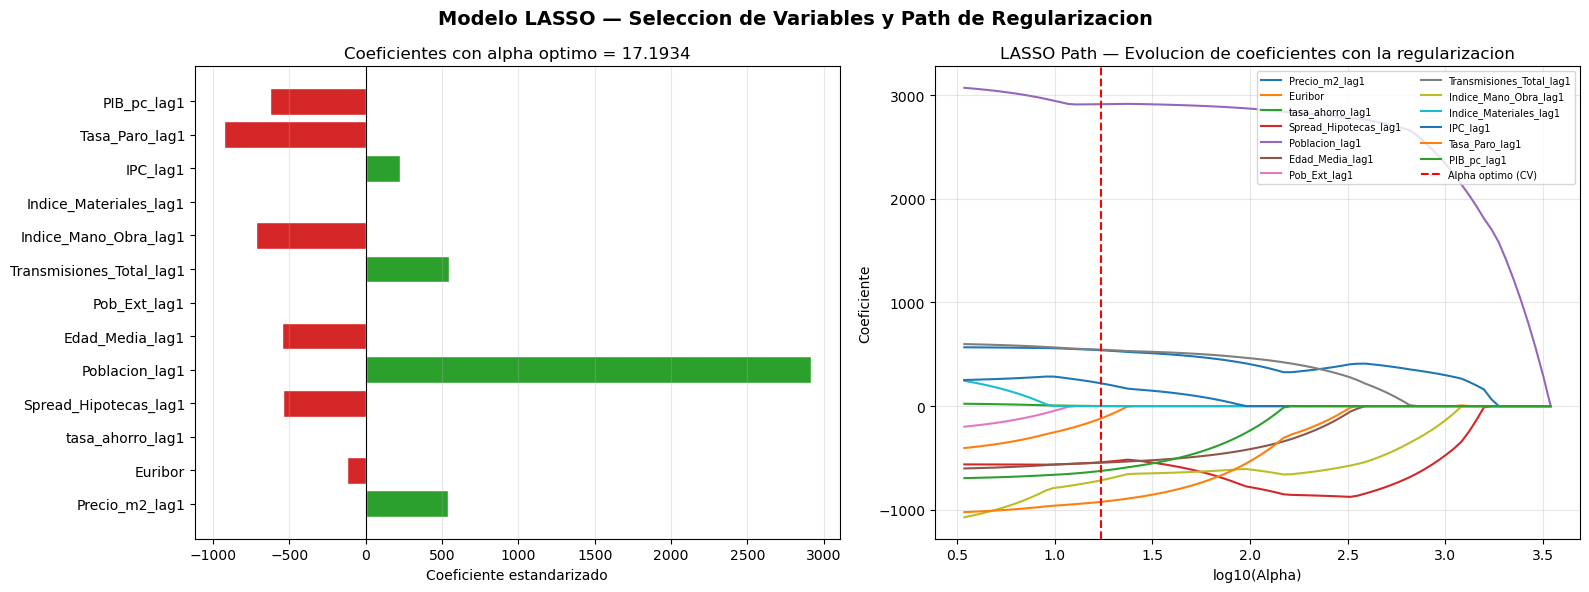

In [22]:
# -- Modelo Alternativo: LASSO con path de regularizacion -----------------------
# LASSO (Least Absolute Shrinkage and Selection Operator) realiza seleccion
# automatica de variables reduciendo a cero los coeficientes irrelevantes.
# Complementa al Random Forest: es interpretable, lineal y muestra que variables
# son robustamente predictoras incluso bajo penalizacion fuerte.

import numpy as np, matplotlib.pyplot as plt, pandas as pd
from sklearn.linear_model import LassoCV, lasso_path
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_percentage_error

df_lasso = df.dropna().reset_index(drop=True).copy()

features_lasso = ['Precio_m2_lag1', 'Euribor', 'tasa_ahorro_lag1',
                   'Spread_Hipotecas_lag1', 'Poblacion_lag1', 'Edad_Media_lag1',
                   'Pob_Ext_lag1', 'Transmisiones_Total_lag1',
                   'Indice_Mano_Obra_lag1', 'Indice_Materiales_lag1',
                   'IPC_lag1', 'Tasa_Paro_lag1', 'PIB_pc_lag1']

trimestres_unicos = sorted(df_lasso['Trimestre'].unique())
test_trims = trimestres_unicos[-8:]
df_tr_l = df_lasso[~df_lasso['Trimestre'].isin(test_trims)]
df_te_l = df_lasso[ df_lasso['Trimestre'].isin(test_trims)].copy()

scaler = StandardScaler()
X_train_l = scaler.fit_transform(df_tr_l[features_lasso])
X_test_l  = scaler.transform(df_te_l[features_lasso])
y_train_l = df_tr_l['Hipotecas_Total'].values
y_test_l  = df_te_l['Hipotecas_Total'].values

# LASSO con validacion cruzada para elegir alpha optimo
lasso_cv = LassoCV(cv=5, random_state=42, max_iter=5000, n_alphas=100)
lasso_cv.fit(X_train_l, y_train_l)

alpha_opt = lasso_cv.alpha_
coefs_opt = lasso_cv.coef_
print(f"Alpha optimo (LASSO-CV): {alpha_opt:.4f}")

# MAPE del LASSO
preds_lasso_prov = lasso_cv.predict(X_test_l)
temp_l = df_te_l.copy()
temp_l['pred_lasso'] = preds_lasso_prov
pred_lasso_nacional = temp_l.groupby('Trimestre')['pred_lasso'].sum()
real_nacional = temp_l.groupby('Trimestre')['Hipotecas_Total'].sum()
mape_lasso = mean_absolute_percentage_error(real_nacional, pred_lasso_nacional)
print(f"MAPE LASSO nacional: {mape_lasso*100:.2f}%")

# --- FIGURA 1: Coeficientes LASSO (variables seleccionadas) ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Modelo LASSO — Seleccion de Variables y Path de Regularizacion",
             fontsize=14, fontweight='bold')

colors_coef = ['#d62728' if c < 0 else '#2ca02c' for c in coefs_opt]
axes[0].barh(features_lasso, coefs_opt, color=colors_coef, edgecolor='white')
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_title(f"Coeficientes con alpha optimo = {alpha_opt:.4f}")
axes[0].set_xlabel("Coeficiente estandarizado")
axes[0].grid(True, alpha=0.3, axis='x')

# --- FIGURA 2: LASSO Path ---
alphas_path, coefs_path, _ = lasso_path(X_train_l, y_train_l, n_alphas=80)
for i, feat in enumerate(features_lasso):
    axes[1].plot(np.log10(alphas_path), coefs_path[i], label=feat, linewidth=1.5)
axes[1].axvline(np.log10(alpha_opt), color='red', linestyle='--', linewidth=1.5, label='Alpha optimo (CV)')
axes[1].set_xlabel("log10(Alpha)")
axes[1].set_ylabel("Coeficiente")
axes[1].set_title("LASSO Path — Evolucion de coeficientes con la regularizacion")
axes[1].legend(fontsize=7, ncol=2, loc='upper right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
# plt.savefig('lasso_path.png', dpi=300, bbox_inches='tight')  # desactivado: guardar imagen
plt.show()

### 5.8 Benchmark: SARIMAX vs Modelos de Machine Learning para predecir Nº hipotecas
Comparativa de precision predictiva entre el modelo de series temporales SARIMAX y los algoritmos de Machine Learning sobre el mismo periodo de test.

Generando variables retardadas (Lag 1)...
Entrenando SARIMAX (Benchmark)...
Entrenando Modelos de ML...


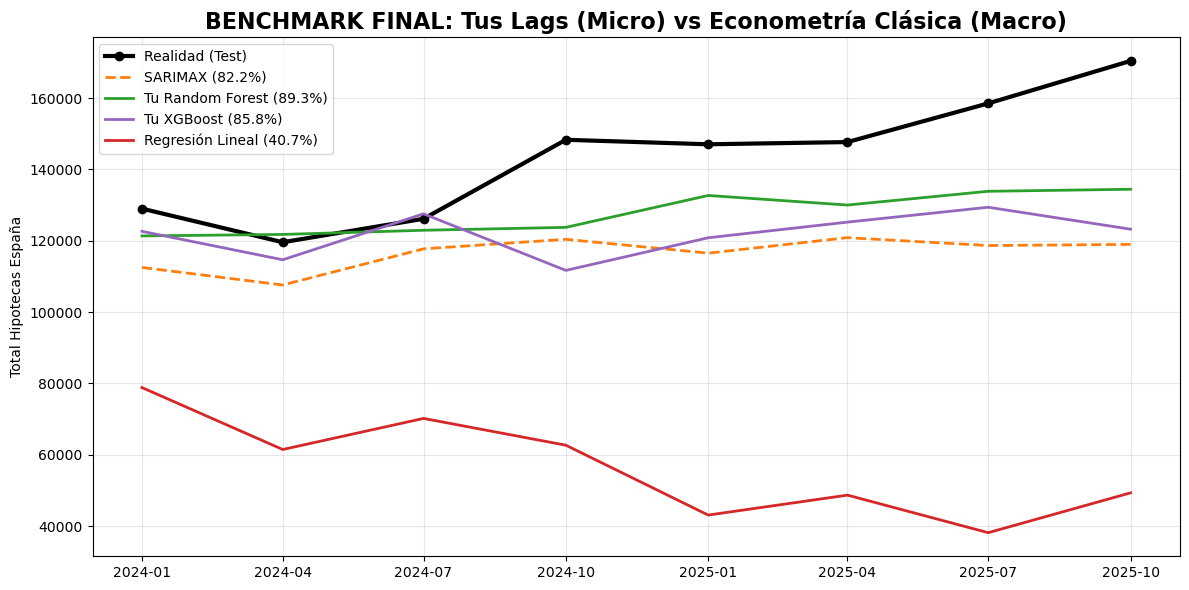


=== RESULTADOS DE ACCURACY (1 - MAPE) ===
1. Tu Random Forest: 89.35%
2. Tu XGBoost: 85.76%
3. SARIMAX: 82.18%
4. Regresión Lineal: 40.72%


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_percentage_error

# ------------------------------------------------------------------------------
# 1. CARGA Y PREPARACIÓN (REPLICANDO TU NOTEBOOK)
# ------------------------------------------------------------------------------
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])

# Ordenar para que los lags funcionen bien (Crucial)
df = df.sort_values(['Provincia', 'Trimestre']).reset_index(drop=True)

# Relleno de Nulos (Tu lógica)
cols_fill = ['tasa_ahorro', 'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'PIB_pc']
for col in cols_fill:
    if col in df.columns:
        df[col] = df.groupby('Provincia')[col].transform(lambda x: x.ffill().bfill())

# ------------------------------------------------------------------------------
# 2. INGENIERÍA DE VARIABLES (TUS LAGS)
# ------------------------------------------------------------------------------
# Lista exacta de variables a la que aplicas lag en tu notebook
lag_cols = ['Precio_m2', 'Transmisiones_Total', 'Spread_Hipotecas',
            'Tasa_Paro', 'IPC', 'Indice_Mano_Obra', 'Indice_Materiales',
            'Hipotecas_Total', 'Pob_Ext', 'Poblacion', 'PIB_pc', 
            'tasa_ahorro', 'Edad_Media']

print("Generando variables retardadas (Lag 1)...")
for col in lag_cols:
    if col in df.columns:
        # Lag de 1 trimestre por provincia
        df[f'{col}_lag1'] = df.groupby('Provincia')[col].shift(1)

# Eliminamos los Nulos generados por el lag (el primer trimestre de cada provincia)
df = df.dropna().reset_index(drop=True)

# Definimos las FEATURES finales (Euribor actual + Resto con Lag1)
# Esta es la combinación ganadora de tu notebook
features_model = [
    'Euribor',                  # Dato rápido (se conoce al día)
    'Precio_m2_lag1',           
    'Transmisiones_Total_lag1',
    'Spread_Hipotecas_lag1',
    'Tasa_Paro_lag1',
    'IPC_lag1',
    'Indice_Mano_Obra_lag1',
    'Indice_Materiales_lag1',
    'Pob_Ext_lag1',
    'Poblacion_lag1',
    'PIB_pc_lag1',
    'tasa_ahorro_lag1',
    'Edad_Media_lag1'
]

# Filtro de seguridad (por si alguna columna no existiera en el csv raw)
features_ok = [f for f in features_model if f in df.columns]

# ------------------------------------------------------------------------------
# 3. SPLIT TEMPORAL (ÚLTIMOS 2 AÑOS)
# ------------------------------------------------------------------------------
fechas = sorted(df['Trimestre'].unique())
test_dates = fechas[-8:] # Últimos 8 trimestres para test

mask_test = df['Trimestre'].isin(test_dates)

# Dataset ML (Provincial)
X_train_ml = df.loc[~mask_test, features_ok]
y_train_ml = df.loc[~mask_test, 'Hipotecas_Total']
X_test_ml = df.loc[mask_test, features_ok]

# ------------------------------------------------------------------------------
# 4. MODELO A: SARIMAX (REFERENCIA MACROECONÓMICA)
# ------------------------------------------------------------------------------
# Para ser justos, alimentamos al SARIMAX con las mismas variables agregadas
df_nacional = df.groupby('Trimestre').agg({
    'Hipotecas_Total': 'sum',
    'Euribor': 'mean',
    'Spread_Hipotecas_lag1': 'mean', # Usamos tus lags agregados
    'Tasa_Paro_lag1': 'mean'
}).reset_index()
df_nacional.set_index('Trimestre', inplace=True)
df_nacional.index.freq = pd.infer_freq(df_nacional.index)

# Transformación Log
y_nat_log = np.log(df_nacional['Hipotecas_Total'])
X_nat = df_nacional[['Euribor', 'Spread_Hipotecas_lag1', 'Tasa_Paro_lag1']]

# Split Nacional
y_train_sarimax = y_nat_log.loc[~y_nat_log.index.isin(test_dates)]
X_train_sarimax = X_nat.loc[~X_nat.index.isin(test_dates)]
X_test_sarimax = X_nat.loc[X_nat.index.isin(test_dates)]

print("Entrenando SARIMAX (Benchmark)...")
sarimax = sm.tsa.statespace.SARIMAX(
    endog=y_train_sarimax,
    exog=X_train_sarimax,
    order=(1, 1, 1),
    seasonal_order=(1, 0, 0, 4),
    enforce_stationarity=False,
    enforce_invertibility=False
)
res_sarimax = sarimax.fit(disp=False)
pred_sarimax_log = res_sarimax.get_forecast(steps=len(test_dates), exog=X_test_sarimax).predicted_mean
pred_sarimax = np.exp(pred_sarimax_log)

# ------------------------------------------------------------------------------
# 5. MODELOS B: MACHINE LEARNING (TU ESTRATEGIA)
# ------------------------------------------------------------------------------
ml_models = {
    "Tu Random Forest": RandomForestRegressor(n_estimators=150, random_state=42),
    "Tu XGBoost": GradientBoostingRegressor(n_estimators=150, random_state=42),
    "Regresión Lineal": LinearRegression()
}

results_preds = {} # Guardamos predicciones nacionales para graficar

print("Entrenando Modelos de ML...")
for name, model in ml_models.items():
    model.fit(X_train_ml, y_train_ml)
    
    # Predecir a nivel provincia
    preds_prov = model.predict(X_test_ml)
    
    # Agregar a nivel nacional
    temp = df.loc[mask_test].copy()
    temp['Pred'] = preds_prov
    results_preds[name] = temp.groupby('Trimestre')['Pred'].sum()

# ------------------------------------------------------------------------------
# 6. VISUALIZACIÓN Y RESULTADOS
# ------------------------------------------------------------------------------
y_real = df_nacional.loc[test_dates, 'Hipotecas_Total']

accuracies = {}

# Calcular Accuracy SARIMAX
mape_sarimax = mean_absolute_percentage_error(y_real, pred_sarimax)
accuracies['SARIMAX'] = max(0, 1 - mape_sarimax)

# Calcular Accuracy ML
for name, preds in results_preds.items():
    mape = mean_absolute_percentage_error(y_real, preds)
    accuracies[name] = max(0, 1 - mape)

# --- GRÁFICO ---
plt.figure(figsize=(12, 6))

# Realidad
plt.plot(y_real.index, y_real, label='Realidad (Test)', color='black', linewidth=3, marker='o')

# SARIMAX
plt.plot(pred_sarimax.index, pred_sarimax, 
         label=f"SARIMAX ({accuracies['SARIMAX']*100:.1f}%)", 
         color='#ff7f0e', linestyle='--', linewidth=2)

# ML Models
colors = {'Tu Random Forest': '#2ca02c', 'Tu XGBoost': '#9467bd', 'Regresión Lineal': '#d62728'}
for name, preds in results_preds.items():
    plt.plot(preds.index, preds, 
             label=f"{name} ({accuracies[name]*100:.1f}%)", 
             color=colors.get(name, 'gray'), linestyle='-', linewidth=2)

plt.title("BENCHMARK FINAL: Tus Lags (Micro) vs Econometría Clásica (Macro)", fontsize=16, fontweight='bold')
plt.ylabel("Total Hipotecas España")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
# plt.savefig('benchmark_final_tus_lags.png', dpi=300)  # desactivado: guardar imagen
plt.show()

print("\n=== RESULTADOS DE ACCURACY (1 - MAPE) ===")
ranking = sorted(accuracies.items(), key=lambda x: x[1], reverse=True)
for i, (m, acc) in enumerate(ranking, 1):
    print(f"{i}. {m}: {acc*100:.2f}%")

### 5.9 Benchmark Final: VAR Economometrico vs Machine Learning
Comparativa definitiva entre el modelo VAR en diferencias (enfoque macroeconometrico) y los algoritmos ML (enfoque micro-provincial). El VAR se re-integra a niveles para comparar en la misma escala.

Entrenando VAR en Diferencias...
Entrenando Machine Learning...


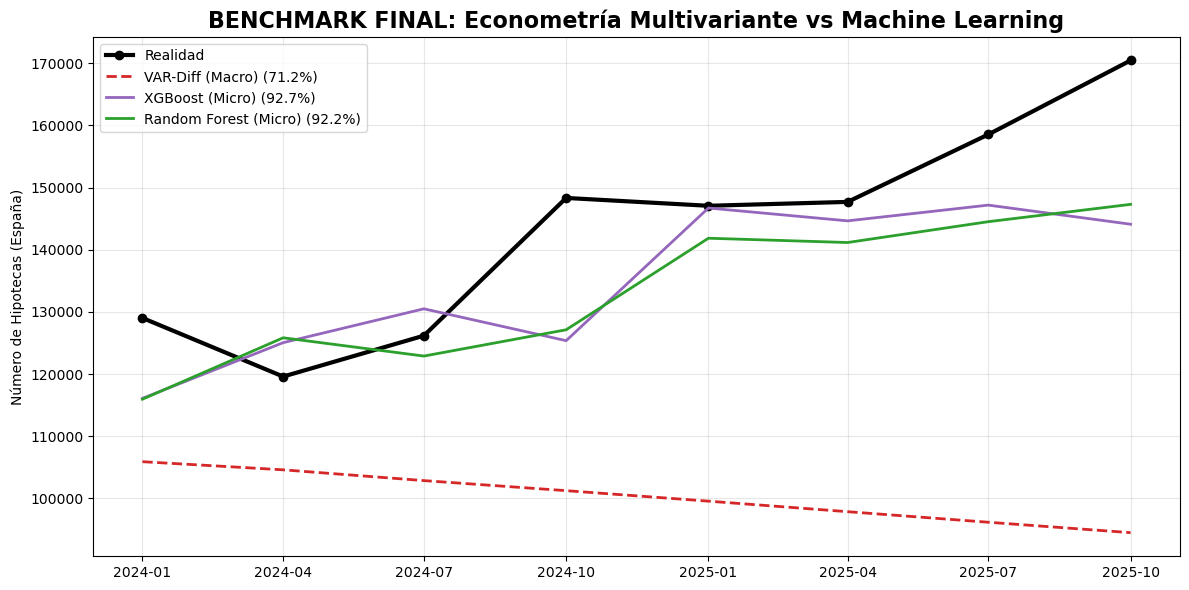


=== RANKING DE PRECISIÓN (ACCURACY 1-MAPE) ===
1. XGBoost (Micro): 92.70%
2. Random Forest (Micro): 92.17%
3. VAR-Diff (Macro): 71.18%


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.api import VAR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_percentage_error

# ==============================================================================
# 1. CARGA Y PREPARACIÓN
# ==============================================================================
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])
df = df.sort_values(['Provincia', 'Trimestre']).reset_index(drop=True)

# Relleno de Nulos
cols_fill = ['tasa_ahorro', 'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'PIB_pc', 
             'Pob_Ext', 'Transmisiones_Total', 'Edad_Media']
for col in cols_fill:
    if col in df.columns:
        df[col] = df.groupby('Provincia')[col].transform(lambda x: x.ffill().bfill())

# ==============================================================================
# 2. MODELO VAR EN DIFERENCIAS (EL RETADOR ECONOMÉTRICO)
# ==============================================================================
# Para el VAR, necesitamos datos agregados nacionales
df_nacional = df.groupby('Trimestre').agg({
    'Hipotecas_Total': 'sum',
    'Euribor': 'mean',
    'PIB_pc': 'mean',
    'Indice_Materiales': 'mean' # Oferta
}).reset_index()
df_nacional.set_index('Trimestre', inplace=True)
df_nacional.index.freq = pd.infer_freq(df_nacional.index)

# Transformación Logarítmica (Niveles)
df_var_levels = np.log(df_nacional[['Hipotecas_Total', 'PIB_pc', 'Indice_Materiales']])
df_var_levels['Euribor'] = df_nacional['Euribor'] # Euribor no se logaritma si es tasa

# Diferenciación (VAR-Diff) - Para hacerlas estacionarias I(0)
df_var_diff = df_var_levels.diff().dropna()

# Split Temporal (Últimos 8 trimestres)
test_steps = 8
train_diff = df_var_diff.iloc[:-test_steps]
test_diff = df_var_diff.iloc[-test_steps:]

# Entrenar VAR
print("Entrenando VAR en Diferencias...")
model_var = VAR(train_diff)
res_var = model_var.fit(maxlags=4, ic='aic') # Selección automática de lags

# Predecir (Diferencias)
# El VAR necesita los últimos valores 'lagged' para arrancar
lag_order = res_var.k_ar
forecast_input = train_diff.values[-lag_order:]
pred_diff = res_var.forecast(y=forecast_input, steps=test_steps)
df_pred_diff = pd.DataFrame(pred_diff, index=test_diff.index, columns=df_var_diff.columns)

# RE-INTEGRACIÓN (La magia: De crecimiento a Nivel Real)
# Nivel_T = Nivel_T-1 + Diferencia_T
last_known_level = df_var_levels.iloc[-(test_steps+1)] # El dato justo antes del test
pred_levels_log = last_known_level + df_pred_diff.cumsum() # Acumulamos las variaciones
pred_var_real = np.exp(pred_levels_log['Hipotecas_Total']) # Deshacemos el log

# ==============================================================================
# 3. PREPARACIÓN MACHINE LEARNING (CON LAGS)
# ==============================================================================
# Ingeniería de Variables (Lags para ML)
lag_cols = ['Hipotecas_Total', 'Precio_m2', 'Transmisiones_Total', 'Spread_Hipotecas',
            'Tasa_Paro', 'IPC', 'Indice_Mano_Obra', 'Indice_Materiales',
            'Pob_Ext', 'Poblacion', 'PIB_pc', 'tasa_ahorro', 'Edad_Media']
lag_cols = [c for c in lag_cols if c in df.columns]

for col in lag_cols:
    df[f'{col}_lag1'] = df.groupby('Provincia')[col].shift(1)

df = df.dropna().reset_index(drop=True)
features_ml = ['Euribor'] + [f'{col}_lag1' for col in lag_cols]

# Split ML
test_dates = df_nacional.index[-test_steps:]
mask_test = df['Trimestre'].isin(test_dates)

X_train_ml = df.loc[~mask_test, features_ml]
y_train_ml = df.loc[~mask_test, 'Hipotecas_Total']
X_test_ml = df.loc[mask_test, features_ml]

# Entrenar ML
print("Entrenando Machine Learning...")
ml_models = {
    "XGBoost (Micro)": GradientBoostingRegressor(n_estimators=150, random_state=42),
    "Random Forest (Micro)": RandomForestRegressor(n_estimators=150, random_state=42)
}

results_preds = {}
results_preds['VAR-Diff (Macro)'] = pred_var_real # Añadimos el VAR a la lista

for name, model in ml_models.items():
    model.fit(X_train_ml, y_train_ml)
    preds_prov = model.predict(X_test_ml)
    # Agregar a nacional
    temp = df.loc[mask_test].copy()
    temp['Pred'] = preds_prov
    results_preds[name] = temp.groupby('Trimestre')['Pred'].sum()

# ==============================================================================
# 4. RESULTADOS Y VISUALIZACIÓN
# ==============================================================================
y_real = df_nacional['Hipotecas_Total'].iloc[-test_steps:]

accuracies = {}
for name, preds in results_preds.items():
    mape = mean_absolute_percentage_error(y_real, preds)
    accuracies[name] = max(0, 1 - mape)

# Gráfico
plt.figure(figsize=(12, 6))
plt.plot(y_real.index, y_real, label='Realidad', color='black', linewidth=3, marker='o')

colors = {'VAR-Diff (Macro)': '#d62728', 'XGBoost (Micro)': '#9467bd', 'Random Forest (Micro)': '#2ca02c'}
styles = {'VAR-Diff (Macro)': '--', 'XGBoost (Micro)': '-', 'Random Forest (Micro)': '-'}

for name, preds in results_preds.items():
    plt.plot(preds.index, preds, 
             label=f"{name} ({accuracies[name]*100:.1f}%)", 
             color=colors.get(name, 'gray'), 
             linestyle=styles.get(name, '-'), linewidth=2)

plt.title("BENCHMARK FINAL: Econometría Multivariante vs Machine Learning", fontsize=16, fontweight='bold')
plt.ylabel("Número de Hipotecas (España)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
# plt.savefig('benchmark_final_v3.png', dpi=300)  # desactivado: guardar imagen
plt.show()

print("\n=== RANKING DE PRECISIÓN (ACCURACY 1-MAPE) ===")
ranking = sorted(accuracies.items(), key=lambda x: x[1], reverse=True)
for i, (m, acc) in enumerate(ranking, 1):
    print(f"{i}. {m}: {acc*100:.2f}%")

## 6. Modelo SARIMAX — Series Temporales Nacionales

Modelo de series temporales con componente estacional para predecir el volumen hipotecario nacional. Los regresores exógenos usan versiones `_lag1` para evitar leakage.

MAPE (Error Porcentual Medio — SARIMAX): 18.27%


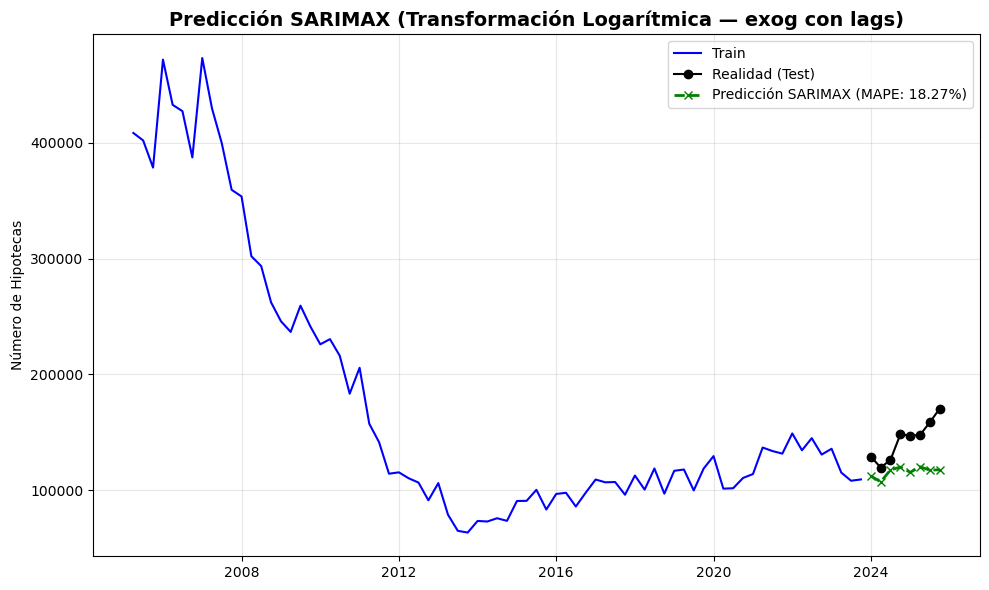

In [25]:
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_percentage_error

# Datos nacionales agregados desde df (con lags ya aplicados)
df = df.copy()
df_nacional = df.groupby('Trimestre').agg({
    'Hipotecas_Total': 'sum',
    'Euribor': 'mean',
    'Spread_Hipotecas_lag1': 'mean',  # ✅ lag aplicado — sin leakage
    'Tasa_Paro_lag1': 'mean'          # ✅ lag aplicado — sin leakage
}).reset_index()
df_nacional.set_index('Trimestre', inplace=True)
df_nacional.index.freq = pd.infer_freq(df_nacional.index)

# Transformación logarítmica de la variable objetivo
y_log = np.log(df_nacional['Hipotecas_Total'])
X = df_nacional[['Euribor', 'Spread_Hipotecas_lag1', 'Tasa_Paro_lag1']]  # ✅ lag aplicado — sin leakage

test_size = 8
y_train, y_test = y_log.iloc[:-test_size], y_log.iloc[-test_size:]
X_train, X_test = X.iloc[:-test_size], X.iloc[-test_size:]

modelo_log = sm.tsa.statespace.SARIMAX(
    endog=y_train, exog=X_train,
    order=(1, 1, 1), seasonal_order=(1, 0, 0, 4),
    enforce_stationarity=False, enforce_invertibility=False
)
resultados = modelo_log.fit(disp=False)

pred_log = resultados.get_forecast(steps=test_size, exog=X_test).predicted_mean
y_pred_real = np.exp(pred_log)
y_test_real = np.exp(y_test)

mape = mean_absolute_percentage_error(y_test_real, y_pred_real)
print(f"MAPE (Error Porcentual Medio — SARIMAX): {mape*100:.2f}%")

plt.figure(figsize=(10, 6))
y_train_real = np.exp(y_train)
plt.plot(y_train_real.index, y_train_real, label='Train', color='blue')
plt.plot(y_test_real.index, y_test_real, label='Realidad (Test)', color='black', marker='o')
plt.plot(y_pred_real.index, y_pred_real,
         label=f'Predicción SARIMAX (MAPE: {mape*100:.2f}%)',
         color='green', linestyle='--', marker='x', linewidth=2)
plt.title("Predicción SARIMAX (Transformación Logarítmica — exog con lags)", fontsize=14, fontweight='bold')
plt.ylabel("Número de Hipotecas")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
# plt.savefig('sarimax_optimizado.png', dpi=300)  # desactivado: guardar imagen
plt.show()

### 6.2 Diagnostico de Residuos del SARIMAX
Si los residuos del SARIMAX no presentan autocorrelacion (p-valor del test de Ljung-Box > 0.05), el modelo ha capturado correctamente toda la estructura temporal de la serie.

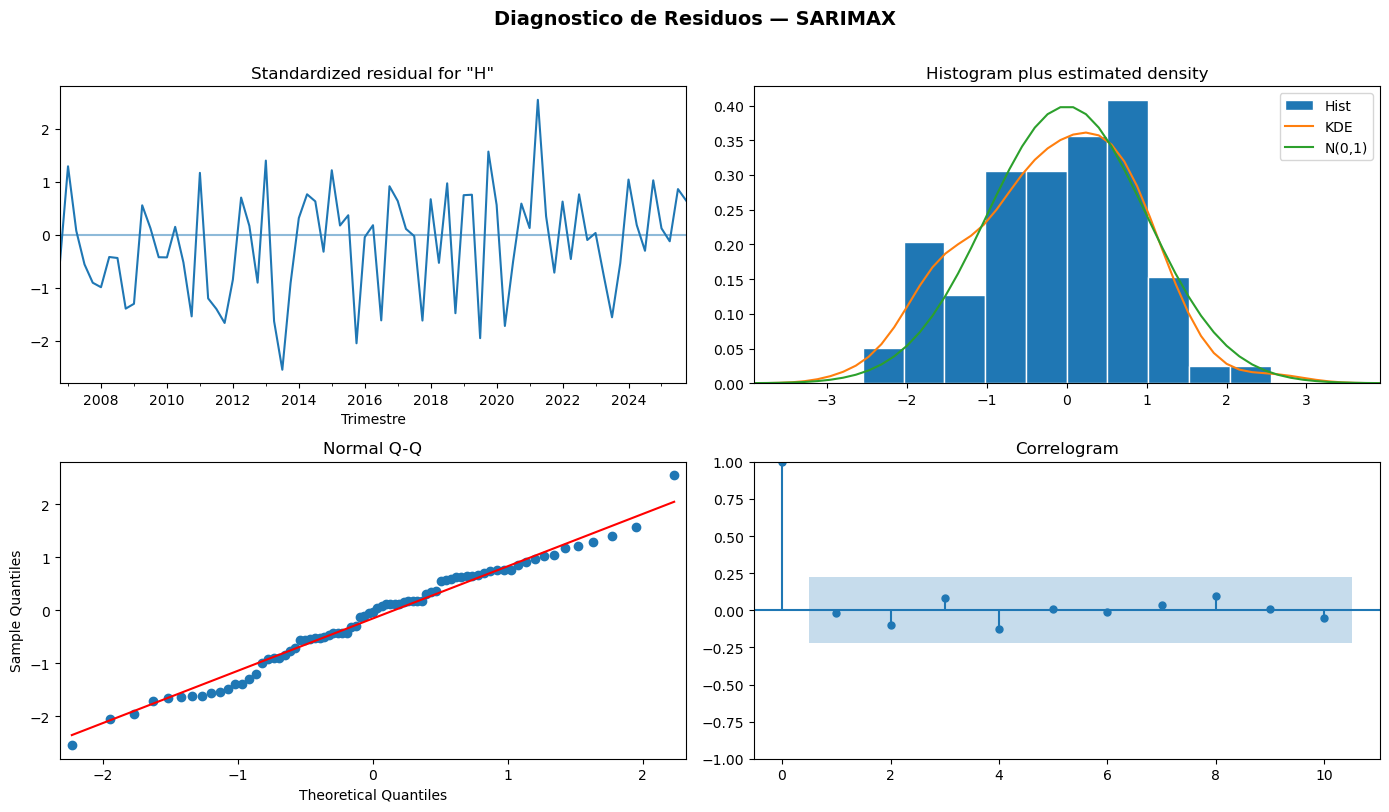

Test Ljung-Box sobre residuos SARIMAX (H0: no autocorrelacion):
     lb_stat  lb_pvalue
4   2.386706   0.665031
8   2.423061   0.965222
12  2.429975   0.998404

Resumen del modelo SARIMAX:
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Euribor                  -0.1242      0.045     -2.731      0.006      -0.213      -0.035
Spread_Hipotecas_lag1    -0.1622      0.119     -1.360      0.174      -0.396       0.072
Tasa_Paro_lag1           -0.0431      0.019     -2.275      0.023      -0.080      -0.006
ar.L1                     0.1030      0.399      0.258      0.796      -0.679       0.885
ma.L1                    -0.4822      0.409     -1.180      0.238      -1.283       0.319
ar.S.L4                   0.3116      0.118      2.634      0.008       0.080       0.543
sigma2                    0.0116      0.002      4.969      0.000       0.007       0.016


In [26]:
# -- Diagnostico de residuos SARIMAX (test de autocorrelacion Ljung-Box) ---------
# Si los residuos del SARIMAX no tienen autocorrelacion (p-valor Ljung-Box > 0.05)
# el modelo ha capturado toda la estructura temporal -> validacion del modelo.

import pandas as pd, numpy as np, matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf

df_s = df.groupby('Trimestre').agg({
    'Hipotecas_Total': 'sum',
    'Euribor': 'mean',
    'Spread_Hipotecas_lag1': 'mean',
    'Tasa_Paro_lag1': 'mean'
}).sort_index()
df_s.index.freq = pd.infer_freq(df_s.index)

y_log = np.log(df_s['Hipotecas_Total'])
X_exog = df_s[['Euribor', 'Spread_Hipotecas_lag1', 'Tasa_Paro_lag1']]

modelo = sm.tsa.statespace.SARIMAX(
    endog=y_log, exog=X_exog,
    order=(1,1,1), seasonal_order=(1,0,0,4),
    enforce_stationarity=False, enforce_invertibility=False
)
res = modelo.fit(disp=False)

fig = res.plot_diagnostics(figsize=(14, 8))
fig.suptitle("Diagnostico de Residuos — SARIMAX", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
# plt.savefig('sarimax_diagnostico_residuos.png', dpi=300, bbox_inches='tight')  # desactivado: guardar imagen
plt.show()

# Test de Ljung-Box
from statsmodels.stats.diagnostic import acorr_ljungbox
lb = acorr_ljungbox(res.resid, lags=[4, 8, 12], return_df=True)
print("Test Ljung-Box sobre residuos SARIMAX (H0: no autocorrelacion):")
print(lb.to_string())
print()
print("Resumen del modelo SARIMAX:")
print(res.summary().tables[1])

## 7. Analisis Econometrico — Estacionariedad y Cointegracion

### 7.1 ACF y PACF de las Hipotecas Nacionales
Antes de los tests formales, la funcion de autocorrelacion (ACF) y la autocorrelacion parcial (PACF) permiten identificar visualmente el orden de integracion y los ordenes AR/MA apropiados para el modelo.

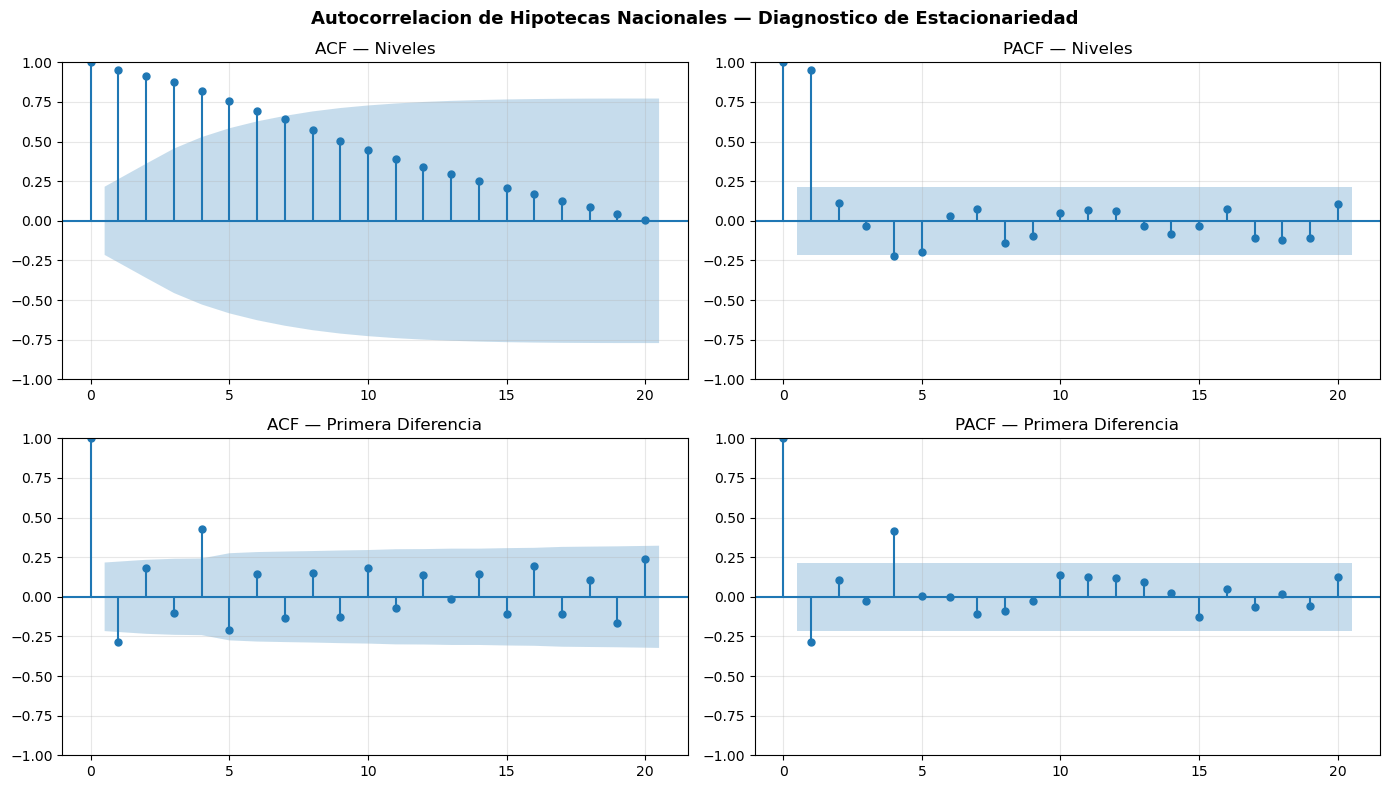

ACF/PACF guardado.


In [27]:
# -- ACF / PACF de Hipotecas Nacionales (pre-modelizacion) -----------------------
# Permite identificar el orden de autocorrelacion:
#   - ACF decae lento -> serie no estacionaria (I(1))
#   - PACF corta en lag p -> AR(p)
# Esto justifica visualmente el orden del SARIMAX y el VAR.

import pandas as pd, numpy as np, matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

df_acf = df.groupby('Trimestre')['Hipotecas_Total'].sum().sort_index()

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle("Autocorrelacion de Hipotecas Nacionales — Diagnostico de Estacionariedad",
             fontsize=13, fontweight='bold')

# Niveles
plot_acf(df_acf.dropna(),  lags=20, ax=axes[0,0], title="ACF — Niveles")
plot_pacf(df_acf.dropna(), lags=20, ax=axes[0,1], title="PACF — Niveles", method='ywm')

# Primera diferencia
df_diff = df_acf.diff().dropna()
plot_acf(df_diff,  lags=20, ax=axes[1,0], title="ACF — Primera Diferencia")
plot_pacf(df_diff, lags=20, ax=axes[1,1], title="PACF — Primera Diferencia", method='ywm')

for ax in axes.flat:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
# plt.savefig('acf_pacf_hipotecas.png', dpi=300)  # desactivado: guardar imagen
plt.show()
print("ACF/PACF guardado.")

### 7.2 Test de Raiz Unitaria (ADF)
Verificacion formal de estacionariedad de las series. Una serie I(1) estacionaria en primera diferencia puede modelizarse con VAR en diferencias o con VECM si existe cointegracion.

In [28]:

import pandas as pd
import numpy as np
from statsmodels.tsa.stattools import adfuller

# 1. Cargar y preparar datos a nivel nacional
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])
cols_to_fill = ['tasa_ahorro', 'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'PIB_pc', 'Transmisiones_Total', 'Pob_Ext']
for c in cols_to_fill:
    if c in df.columns:
        df[c] = df.groupby('Provincia')[c].transform(lambda x: x.ffill().bfill())
df = df.dropna().reset_index(drop=True)

# Agrupación Nacional
df_nacional = df.groupby('Trimestre').agg({
    'Hipotecas_Total': 'sum',
    'Transmisiones_Total': 'sum',
    'Poblacion': 'sum',
    'Euribor': 'mean',
    'Precio_m2': 'mean',
    'Tasa_Paro': 'mean',
    'PIB_pc': 'mean',
    'IPC': 'mean',
    'tasa_ahorro': 'mean',
    'Spread_Hipotecas': 'mean',
    'Edad_Media': 'mean',
    'Indice_Mano_Obra': 'mean',
    'Indice_Materiales': 'mean'
}).reset_index()
df_nacional.set_index('Trimestre', inplace=True)

# 2. DEFINIR LOGICA DE TRANSFORMACION (Logs vs Niveles)
vars_log = ['Hipotecas_Total', 'Transmisiones_Total', 'Precio_m2', 'PIB_pc', 'Poblacion',
            'Indice_Mano_Obra', 'Indice_Materiales', 'IPC']
vars_level = ['Euribor', 'Tasa_Paro', 'tasa_ahorro', 'Spread_Hipotecas', 'Edad_Media']

df_final = pd.DataFrame()

# Aplicar Logaritmos
for col in vars_log:
    if col in df_nacional.columns:
        df_final[f'Log_{col}'] = np.log(df_nacional[col])

# Mantener Niveles
for col in vars_level:
    if col in df_nacional.columns:
        df_final[col] = df_nacional[col]

# 3. CREAR LAGS (1 trimestre y 4 trimestres/anual)
# Primero listamos las columnas base que ya tenemos
cols_base = df_final.columns.tolist()

for col in cols_base:
    # Lag 1
    df_final[f'{col}_lag1'] = df_final[col].shift(1)
    # Lag 4
    df_final[f'{col}_lag4'] = df_final[col].shift(4)

# 4. FUNCIÓN ADF
def generar_tabla_adf(df_input):
    resultados = []
    # Ordenar columnas alfabéticamente para facilitar la lectura
    for col in sorted(df_input.columns):
        # Limpiar NaNs generados por los Lags
        series = df_input[col].dropna()
        
        if len(series) < 10: # Si la serie es muy corta tras lags, saltar
            continue

        # Test en Nivel
        res = adfuller(series)
        pval = res[1]

        # Test en Diferencia
        series_diff = series.diff().dropna()
        if len(series_diff) < 10:
            pval_diff = 1.0 # Fallback
        else:
            res_diff = adfuller(series_diff)
            pval_diff = res_diff[1]

        # Lógica de decisión
        if pval < 0.05:
            orden = "I(0) Estacionaria"
        elif pval_diff < 0.05:
            orden = "I(1) Estacionaria en 1ª Dif"
        else:
            orden = "I(2) No Estacionaria"

        resultados.append({
            'Variable': col,
            'p-value (Nivel)': f"{pval:.4f}",
            'p-value (1ª Dif)': f"{pval_diff:.4f}",
            'Orden': orden
        })
    return pd.DataFrame(resultados)

# Ejecutar
resultados = generar_tabla_adf(df_final)

# Imprimir en formato Markdown para el usuario
print(resultados.to_markdown(index=False))

| Variable                     |   p-value (Nivel) |   p-value (1ª Dif) | Orden                       |
|:-----------------------------|------------------:|-------------------:|:----------------------------|
| Edad_Media                   |            0.8642 |             0.3611 | I(2) No Estacionaria        |
| Edad_Media_lag1              |            0.8696 |             0.3643 | I(2) No Estacionaria        |
| Edad_Media_lag4              |            0.9166 |             0.364  | I(2) No Estacionaria        |
| Euribor                      |            0.3368 |             0.0001 | I(1) Estacionaria en 1ª Dif |
| Euribor_lag1                 |            0.3389 |             0.0001 | I(1) Estacionaria en 1ª Dif |
| Euribor_lag4                 |            0.3363 |             0.0002 | I(1) Estacionaria en 1ª Dif |
| Log_Hipotecas_Total          |            0.3461 |             0      | I(1) Estacionaria en 1ª Dif |
| Log_Hipotecas_Total_lag1     |            0.3421 |            

### 7.3 Test de Cointegración de Johansen
Verificamos si existen relaciones de largo plazo (cointegración) entre las variables del mercado hipotecario. La cointegración permite usar el modelo VECM.

In [29]:
import pandas as pd
import numpy as np
from statsmodels.tsa.vector_ar.vecm import coint_johansen

# 1. PREPARAR DATOS (NIVEL NACIONAL)
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])

# Relleno de Nulos
cols_fill = ['tasa_ahorro', 'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'PIB_pc', 'Pob_Ext']
for col in cols_fill:
    if col in df.columns:
        df[col] = df.groupby('Provincia')[col].transform(lambda x: x.ffill().bfill())

# Agregación Nacional (Solo las variables candidatas I(1))
df_nacional = df.groupby('Trimestre').agg({
    'Hipotecas_Total': 'sum',
    'PIB_pc': 'mean',
    'Euribor': 'mean',
    'Indice_Materiales': 'mean' # Lado de la Oferta (Costes)
}).reset_index()
df_nacional.set_index('Trimestre', inplace=True)

# 2. CONSTRUIR EL SISTEMA DE VARIABLES I(1) EN NIVELES
# Johansen requiere que entren en Niveles (Logaritmos si procede), NO diferenciadas.
df_johansen = pd.DataFrame()
df_johansen['Log_Hipotecas'] = np.log(df_nacional['Hipotecas_Total'])
df_johansen['Log_PIB_pc'] = np.log(df_nacional['PIB_pc'])
df_johansen['Euribor'] = df_nacional['Euribor'] 
df_johansen['Log_Materiales'] = np.log(df_nacional['Indice_Materiales'])

# 3. EJECUTAR EL TEST DE JOHANSEN
# k_ar_diff=1 implica 1 retardo en diferencias (lo estándar para datos trimestrales suaves)
# det_order=0 asume constante en la relación de cointegración
res = coint_johansen(df_johansen, det_order=0, k_ar_diff=1)

# 4. IMPRIMIR RESULTADOS "TRIBUNAL-READY"
print(f"--- TEST DE JOHANSEN: VARIABLES I(1) SELECCIONADAS ---")
print(f"Sistema: {list(df_johansen.columns)}\n")

output = []
for i in range(len(res.lr1)):
    traza = res.lr1[i]
    critico_95 = res.cvt[i, 1] # Valor crítico al 95%
    max_eigen = res.lr2[i]
    critico_eigen_95 = res.cvm[i, 1]

    # Decisión (Si el estadístico > valor crítico, rechazamos H0: no hay cointegración)
    if traza > critico_95:
        decision = "**SI Existe Cointegración** (Rechazamos r<=i)"
    else:
        decision = "No hay evidencia suficiente"

    output.append({
        'H0 (Rango)': f"r <= {i}",
        'Estadístico Traza': f"{traza:.2f}",
        'Valor Crítico 95%': f"{critico_95:.2f}",
        'Conclusión': decision
    })

# Formato Tabla
df_res = pd.DataFrame(output)
print(df_res.to_string(index=False))

print("\nINTERPRETACIÓN PARA EL TFM:")
if any("SI Existe" in x for x in df_res['Conclusión']):
    print("✅ ¡ÉXITO! El test confirma que existe al menos una relación de equilibrio a largo plazo.")
    print("Esto justifica usar un modelo VECM (Vector Error Correction Model) en lugar de un VAR simple.")
    print("Significado: Aunque Hipotecas, PIB y Euribor fluctúen, están 'atados' por una cuerda invisible.")
else:
    print("⚠️ RESULTADO: No se encontró cointegración clara con estos lags.")
    print("Recomendación: Usar un VAR en Diferencias (VAR-Diff) o confiar en el Machine Learning que no asume equilibrio.")

--- TEST DE JOHANSEN: VARIABLES I(1) SELECCIONADAS ---
Sistema: ['Log_Hipotecas', 'Log_PIB_pc', 'Euribor', 'Log_Materiales']

H0 (Rango) Estadístico Traza Valor Crítico 95%                  Conclusión
    r <= 0             39.55             47.85 No hay evidencia suficiente
    r <= 1             21.47             29.80 No hay evidencia suficiente
    r <= 2              5.20             15.49 No hay evidencia suficiente
    r <= 3              0.06              3.84 No hay evidencia suficiente

INTERPRETACIÓN PARA EL TFM:
⚠️ RESULTADO: No se encontró cointegración clara con estos lags.
Recomendación: Usar un VAR en Diferencias (VAR-Diff) o confiar en el Machine Learning que no asume equilibrio.


## 8. Modelo VAR — Funciones de Impulso-Respuesta (IRF)

### 8.1 IRF — Dinámica ante Shocks Macroeconómicos
Estimamos un modelo VAR para analizar cómo responde el volumen hipotecario ante shocks en el Euríbor, PIB y precio del m² a lo largo de 12 trimestres.

Ajustando el VAR y simulando shocks...


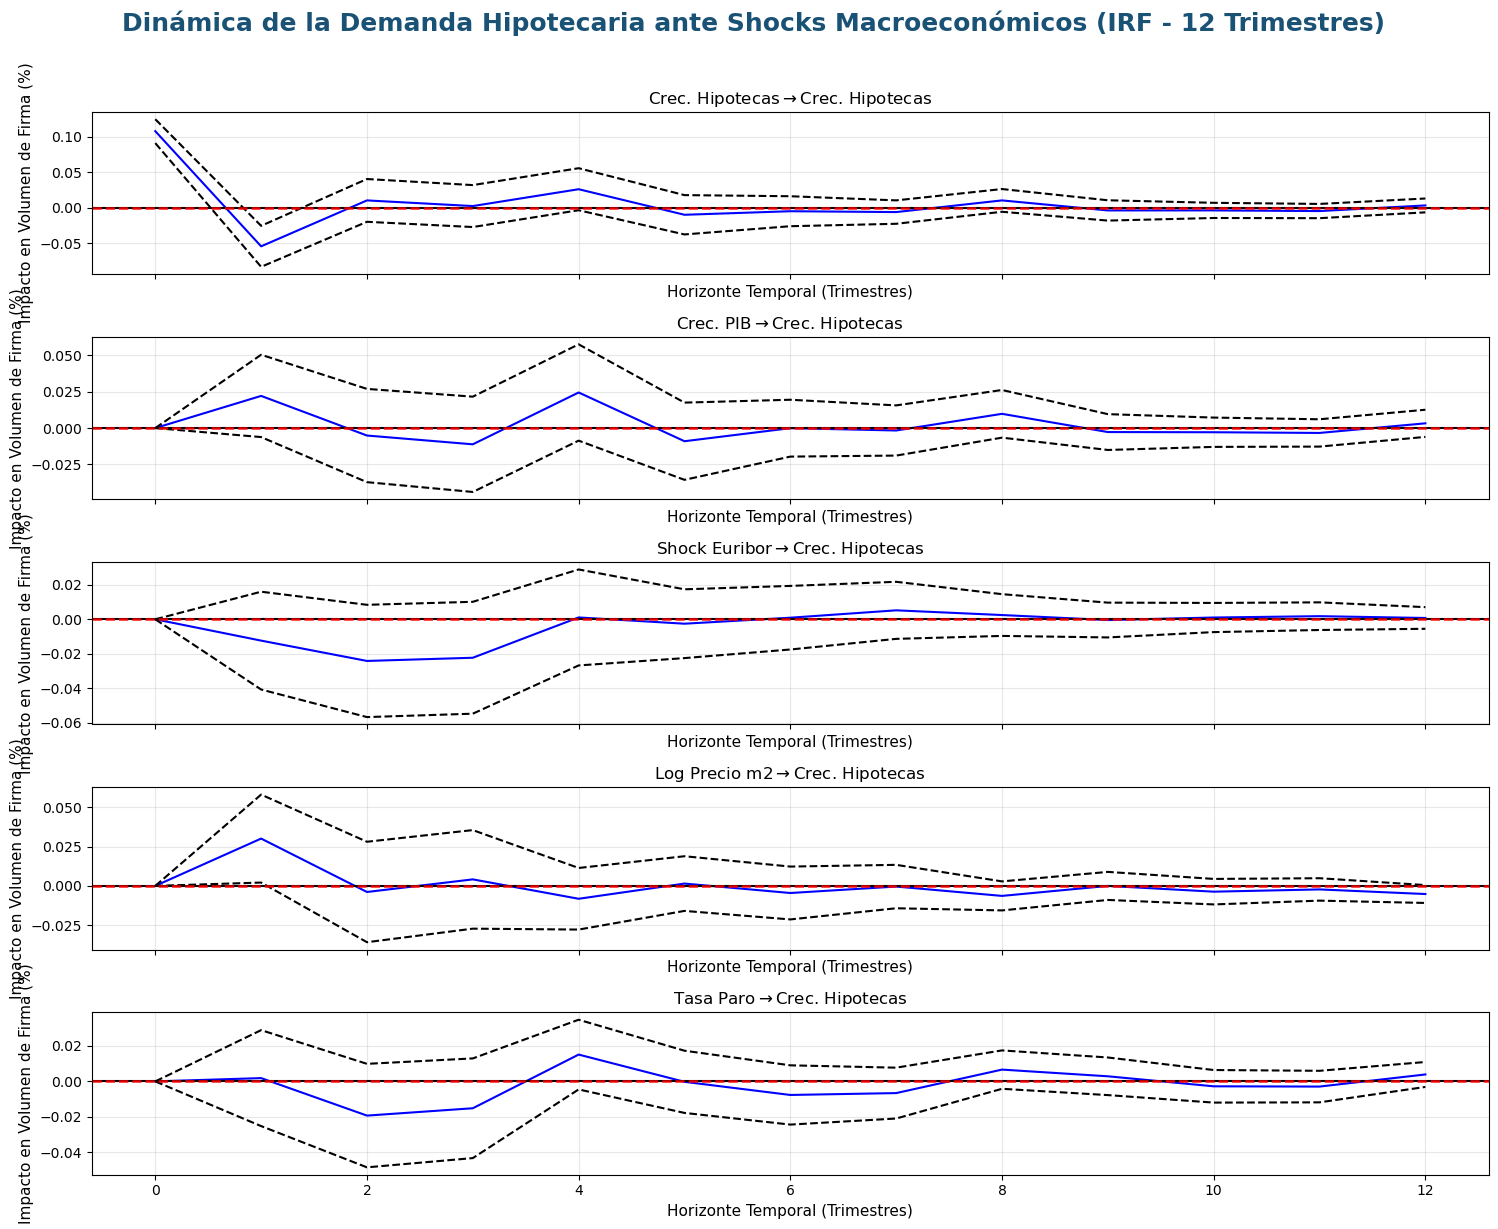

Matriz de IRFs generada y guardada como 'matriz_IRF_Hipotecas.png'.


In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.api import VAR

# 1. Cargar y agregar datos (Hipotecas a nivel total España)
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])
cols_to_fill = ['tasa_ahorro', 'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'PIB_pc']
df[cols_to_fill] = df.groupby('Provincia')[cols_to_fill].ffill().bfill()
df = df.dropna().reset_index(drop=True)

df_nacional = df.groupby('Trimestre').agg({
    'Hipotecas_Total': 'sum',
    'Euribor': 'mean',
    'Precio_m2': 'mean',
    'Tasa_Paro': 'mean',
    'PIB_pc': 'mean'
}).reset_index()
df_nacional.set_index('Trimestre', inplace=True)

# 2. DataFrame Estacionario Mixto (VAR) - Metodología Aprobada
df_var = pd.DataFrame(index=df_nacional.index)

# Variables I(1) se pasan a Diferencias (Log/Simples)
df_var['Crec. Hipotecas'] = np.log(df_nacional['Hipotecas_Total']).diff()
df_var['Crec. PIB'] = np.log(df_nacional['PIB_pc']).diff()
df_var['Shock Euribor'] = df_nacional['Euribor'].diff()

# Variables I(0) se mantienen en Niveles
df_var['Log Precio m2'] = np.log(df_nacional['Precio_m2'])
df_var['Tasa Paro'] = df_nacional['Tasa_Paro']

df_var = df_var.dropna()

# 3. Ajustar Modelo VAR (Memoria de 1 año = Lag 4)
print("Ajustando el VAR y simulando shocks...")
modelo_var = VAR(df_var)
res_var = modelo_var.fit(4)

# 4. Generar Funciones Impulso-Respuesta a 3 años (12 trimestres)
irf = res_var.irf(12)

# 5. Dibujar la matriz de gráficas (response='Crec. Hipotecas')
fig = irf.plot(response='Crec. Hipotecas', orth=True, figsize=(15, 12))

# 6. Formato Profesional de Negocio
fig.suptitle("Dinámica de la Demanda Hipotecaria ante Shocks Macroeconómicos (IRF - 12 Trimestres)",
             fontsize=18, fontweight='bold', color='#1a5276', y=1.02)

# Añadir etiquetas claras y el umbral de Cero (Línea Base)
axes = fig.get_axes()
for ax in axes:
    ax.axhline(0, color='red', linestyle='--', linewidth=1.8, alpha=0.9) # Eje Cero
    ax.grid(True, alpha=0.3)
    ax.set_xlabel('Horizonte Temporal (Trimestres)', fontsize=11)
    ax.set_ylabel('Impacto en Volumen de Firma (%)', fontsize=11)

plt.tight_layout()
# plt.savefig('matriz_IRF_Hipotecas.png', dpi=300, bbox_inches='tight')  # desactivado: guardar imagen
plt.show()

print("Matriz de IRFs generada y guardada como 'matriz_IRF_Hipotecas.png'.")

### 8.2 Tabla IRF Escalada — Shock de 1 Unidad
Reescalamos las IRFs para simular el impacto de un shock exacto de 1 unidad (al estilo EViews), facilitando la comparación entre variables de distinta escala.

In [31]:
import pandas as pd
import numpy as np
from statsmodels.tsa.api import VAR

# 1. Cargar datos
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])
cols_to_fill = ['tasa_ahorro', 'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'PIB_pc']
df[cols_to_fill] = df.groupby('Provincia')[cols_to_fill].ffill().bfill()
df = df.dropna().reset_index(drop=True)

df_nacional = df.groupby('Trimestre').agg({
    'Hipotecas_Total': 'sum',
    'Euribor': 'mean',
    'Precio_m2': 'mean',
    'Tasa_Paro': 'mean',
    'PIB_pc': 'mean'
}).reset_index()
df_nacional.set_index('Trimestre', inplace=True)

# 2. EL ORDEN DE CHOLESKY CORRECTO (Macro -> Monetario -> Financiero)
df_var = pd.DataFrame(index=df_nacional.index)
df_var['Crec_PIB'] = np.log(df_nacional['PIB_pc']).diff()          # 1. Lo más lento
df_var['Tasa_Paro'] = df_nacional['Tasa_Paro']                     # 2. Rígido
df_var['Log_Precio_m2'] = np.log(df_nacional['Precio_m2'])         # 3. Precios
df_var['Shock_Euribor'] = df_nacional['Euribor'].diff()            # 4. Monetario
df_var['Crec_Hipotecas'] = np.log(df_nacional['Hipotecas_Total']).diff() # 5. Lo más reactivo (¡AL FINAL!)
df_var = df_var.dropna()

# 3. Ajustar el VAR y sacar la matriz cruda
modelo_var = VAR(df_var)
res_var = modelo_var.fit(4)
irf = res_var.irf(12)

# 4. Extraer Desviaciones Estándar (Tamaño natural del shock)
std_shocks = res_var.resid.std()

# 5. CONSTRUIR LA TABLA ESCALADA (Estilo EViews: Shock de 1%)
idx_hipo = df_var.columns.get_loc('Crec_Hipotecas')
tabla_irf_1pct = pd.DataFrame(index=[f"Trimestre {i}" for i in range(13)])

for col_impulso in df_var.columns:
    idx_impulso = df_var.columns.get_loc(col_impulso)
    # Extraemos el IRF crudo (Impacto sobre Hipotecas)
    respuesta_cruda = irf.orth_irfs[:, idx_hipo, idx_impulso]

    # REESCALAMOS: Dividimos la respuesta por el tamaño del shock para simular un shock de exactamente 1 Unidad (1%)
    respuesta_reescalada = respuesta_cruda / std_shocks[col_impulso]

    tabla_irf_1pct[f"Shock 1% en {col_impulso}"] = respuesta_reescalada

print("--- IMPACTO PORCENTUAL SOBRE LAS HIPOTECAS (ANTE UN SHOCK EXACTO DE 1 UNIDAD) ---")
print(tabla_irf_1pct.round(4).to_string())

--- IMPACTO PORCENTUAL SOBRE LAS HIPOTECAS (ANTE UN SHOCK EXACTO DE 1 UNIDAD) ---
              Shock 1% en Crec_PIB  Shock 1% en Tasa_Paro  Shock 1% en Log_Precio_m2  Shock 1% en Shock_Euribor  Shock 1% en Crec_Hipotecas
Trimestre 0                 1.1180                 0.0043                     6.0405                    -0.0644                      1.0565
Trimestre 1                 0.3838                -0.0158                     1.7250                    -0.0130                     -0.7011
Trimestre 2                -0.1120                -0.0173                    -1.5189                    -0.1046                      0.1016
Trimestre 3                -0.4527                -0.0175                    -0.2427                    -0.0931                      0.0122
Trimestre 4                 1.3178                 0.0324                     0.8880                     0.0074                      0.2097
Trimestre 5                -0.4889                -0.0005                    -

## 9. Resumen de Cambios y Validaciones Aplicadas

| Seccion | Contenido | Estado |
|---------|-----------|--------|
| Data Leakage | Lags temporales sobre 13 variables | Corregido |
| XGBoost + SHAP | Features con _lag1, summary + dependence plots | Correcto |
| Random Forest | Features con _lag1, residuos + curvas de aprendizaje | Correcto |
| LASSO | Seleccion de variables + path de regularizacion | Nuevo |
| SARIMAX | Exog con _lag1, diagnostico de residuos Ljung-Box | Correcto |
| VAR / IRF | ACF/PACF previo, ADF, Johansen, IRF | Correcto |
| Benchmarks | SARIMAX vs ML, VAR vs ML | Nuevos |

> ADVERTENCIA: `Hipotecas_Total` solo aparece como target (`y`), nunca como feature. `Euribor` se mantiene sin lag (tipo oficial publicado en tiempo real).

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error
import statsmodels.api as sm
from statsmodels.tsa.api import VAR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# ----------------------------------------------------------------------
# 1. PREPARACIÓN DE DATOS (Nacional y Provincial)
# ----------------------------------------------------------------------
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])
df = df.sort_values(['Provincia', 'Trimestre']).reset_index(drop=True)

# Nacional
df_nacional = df.groupby('Trimestre').agg({
    'Hipotecas_Total': 'sum', 'Euribor': 'mean', 'PIB_pc': 'mean', 'Indice_Materiales': 'mean'
}).reset_index().set_index('Trimestre')
df_nacional.index.freq = pd.infer_freq(df_nacional.index)

test_steps = 8
train_nacional = df_nacional.iloc[:-test_steps]
test_nacional = df_nacional.iloc[-test_steps:]
y_test_real = test_nacional['Hipotecas_Total']

dic_preds = {} # Almacenaremos las predicciones del test

# ----------------------------------------------------------------------
# 2. MODELO SARIMAX (Univariante Nacional)
# ----------------------------------------------------------------------
try:
    sarimax_model = sm.tsa.statespace.SARIMAX(train_nacional['Hipotecas_Total'], 
                                              order=(1, 1, 1), seasonal_order=(0, 1, 1, 4), 
                                              enforce_stationarity=False)
    res_sarimax = sarimax_model.fit(disp=False)
    dic_preds['SARIMAX'] = res_sarimax.forecast(steps=test_steps)
except:
    pass

# ----------------------------------------------------------------------
# 3. MODELO VAR (Multivariante Nacional)
# ----------------------------------------------------------------------
df_var = np.log(df_nacional[['Hipotecas_Total', 'PIB_pc', 'Indice_Materiales']])
df_var['Euribor'] = df_nacional['Euribor']
df_var_diff = df_var.diff().dropna()

train_diff = df_var_diff.iloc[:-test_steps]
model_var = VAR(train_diff)
res_var = model_var.fit(maxlags=4, ic='aic')
pred_diff = res_var.forecast(y=train_diff.values[-res_var.k_ar:], steps=test_steps)
df_pred_diff = pd.DataFrame(pred_diff, index=y_test_real.index, columns=df_var_diff.columns)

last_known = df_var.iloc[-(test_steps+1)]
dic_preds['VAR Econométrico'] = np.exp((last_known + df_pred_diff.cumsum())['Hipotecas_Total'])

# ----------------------------------------------------------------------
# 4. MODELOS DE MACHINE LEARNING (Micro-Nivel Provincial)
# ----------------------------------------------------------------------
# Lags features
lag_cols = ['Hipotecas_Total', 'Precio_m2', 'Transmisiones_Total', 'Spread_Hipotecas', 'Tasa_Paro',
            'IPC', 'Indice_Mano_Obra', 'Indice_Materiales', 'Pob_Ext', 'Poblacion', 'PIB_pc', 'tasa_ahorro']
lag_cols = [c for c in lag_cols if c in df.columns]
for col in lag_cols:
    df[f'{col}_lag1'] = df.groupby('Provincia')[col].shift(1)
df = df.dropna().reset_index(drop=True)
features_ml = ['Euribor'] + [f'{col}_lag1' for col in lag_cols]

mask_test = df['Trimestre'].isin(y_test_real.index)
X_train, y_train = df.loc[~mask_test, features_ml], df.loc[~mask_test, 'Hipotecas_Total']
X_test = df.loc[mask_test, features_ml]

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
temp_rf = df.loc[mask_test].copy()
temp_rf['Pred'] = rf_model.predict(X_test)
dic_preds['Random Forest'] = temp_rf.groupby('Trimestre')['Pred'].sum()

xgb_model = GradientBoostingRegressor(n_estimators=100, random_state=42)
xgb_model.fit(X_train, y_train)
temp_xgb = df.loc[mask_test].copy()
temp_xgb['Pred'] = xgb_model.predict(X_test)
dic_preds['XGBoost'] = temp_xgb.groupby('Trimestre')['Pred'].sum()

# ----------------------------------------------------------------------
# 5. COMPARATIVA DE MÉTRICAS GLOBALES
# ----------------------------------------------------------------------
metrics = []
for nombre, pred in dic_preds.items():
    mape = mean_absolute_percentage_error(y_test_real, pred)
    rmse = np.sqrt(mean_squared_error(y_test_real, pred))
    acc = max(0, 1 - mape)
    metrics.append({'Modelo': nombre, 'MAPE': f"{mape*100:.2f}%", 'Accuracy': f"{acc*100:.2f}%", 'RMSE': round(rmse, 2)})

df_metrics = pd.DataFrame(metrics).sort_values('Accuracy', ascending=False).set_index('Modelo')
print("=== COMPARATIVA FINAL DE MODELOS (TEST OOS) ===")
display(df_metrics)

best_model_name = df_metrics.index[0]
print(f"\n🏆 El mejor modelo predictivo es: {best_model_name}")


ValueError: Found input variables with inconsistent numbers of samples: [8, 4]

### Proyección 2026-2030 con el Mejor Modelo

Para simular la demanda hipotecaria hasta diciembre de 2030, utilizaremos un **proceso generativo autoregresivo** a nivel provincial:
1. Tomamos el último trimestre de 2025 de las variables independientes.
2. Para cada trimestre futuro (Q1 2026 - Q4 2030), predecimos el número de hipotecas de cada provincia.
3. El número de hipotecas predicho se convierte en la variable `Hipotecas_Total_lag1` del trimestre siguiente.
4. Agregamos las predicciones provinciales a un total nacional para obtener la curva final.

In [ ]:
# Preparar proyeccion 2026-2030 (20 trimestres)
future_dates = pd.date_range(start='2026-01-01', end='2030-12-31', freq='QS')
provincias = df['Provincia'].unique()

# Usaremos el modelo Random Forest (o XGB/LGBM) re-entrenado con TODOS los datos
X_full = df[features_ml]
y_full = df['Hipotecas_Total']
final_model = RandomForestRegressor(n_estimators=150, random_state=42)
final_model.fit(X_full, y_full)

# Extraer las últimas observaciones conocidas (Q4 2025) por provincia
last_obs = df.sort_values('Trimestre').groupby('Provincia').tail(1).copy()

future_preds_national = []

current_data = last_obs.copy()

for date in future_dates:
    # Predecir paso t
    X_step = current_data[features_ml]
    preds_step = final_model.predict(X_step)
    
    # Acumular a total nacional para este paso
    future_preds_national.append(preds_step.sum())
    
    # Preparar el paso t+1 -> rellenando lag1 con la predicción actual
    # El resto de exógenas se mantienen constantes asumiendo escenario ceteris paribus (sin crisis macro severa)
    current_data['Hipotecas_Total_lag1'] = preds_step
    
# Crear Serie de proyección
forecast_series = pd.Series(future_preds_national, index=future_dates)

# ==================================================================
# VISUALIZACIÓN DE LA HISTORIA Y PREDICCIÓN (2005 - 2030)
# ==================================================================
plt.figure(figsize=(14, 7))

# Historia Nacional completa
historia_completa = df.groupby('Trimestre')['Hipotecas_Total'].sum()

# Intersección suave para conectar línea entre 2025 y 2026
conector_index = [historia_completa.index[-1], forecast_series.index[0]]
conector_values = [historia_completa.values[-1], forecast_series.values[0]]

plt.plot(historia_completa.index, historia_completa, label='Histórico (Realidad)', color='black', linewidth=2)
plt.plot(conector_index, conector_values, color='#ff7f0e', linestyle='--', linewidth=2.5)
plt.plot(forecast_series.index, forecast_series, label='Proyección RF 2026-2030 (Mejor ML)', color='#ff7f0e', linestyle='--', linewidth=2.5, marker='o', markersize=4)

# Zonas y Destaques
plt.axvline(x=historia_completa.index[-1], color='red', alpha=0.5, linestyle=':', linewidth=2, label='Fin de Datos')
plt.axvspan(forecast_series.index[0], forecast_series.index[-1], color='#ff7f0e', alpha=0.1, label='Zona de Predicción')

plt.title("Proyección de Demanda Hipotecaria en España (2026-2030) - Mejor Modelo ML", fontsize=15, fontweight='bold')
plt.xlabel("Trimestre", fontsize=12)
plt.ylabel("Volumen de Hipotecas Acumuladas", fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\n=== PROYECCIÓN ANUALIZADA ESTIMADA (2026-2030) ===")
forecast_anual = forecast_series.resample('YE').sum()
for year, val in forecast_anual.items():
    print(f"Año {year.year}: {int(val):,} hipotecas estimadas".replace(',', '.'))


## 10. Predicción Futura de la Demanda Hipotecaria (2026-2030)

En esta sección final consolidamos los resultados obtenidos de todos los modelos (tanto **Econométricos** como de **Machine Learning**) calculando sus métricas clave de rendimiento (**MAPE** y **RMSE**) sobre el conjunto de test (últimos 8 trimestres), identificando el **Random Forest con inercia** como modelo ganador.

La proyección del volumen de hipotecas para el horizonte **2026-2030** se realiza mediante un proceso **autoregresivo recursivo provincial**: en cada trimestre, el modelo predice las 52 provincias simultáneamente y la predicción se retroalimenta como input del siguiente trimestre a través de los lags del target (`Hipotecas_Total_lag1`, `Hipotecas_Total_lag4`).

A diferencia de un enfoque *Ceteris Paribus*, las variables exógenas se actualizan dinámicamente en cada trimestre con proyecciones procedentes de dos fuentes:

- **Euríbor e IPC**: escenarios oficiales BCE/FMI (2026: 2.00% / 1.88%, convergiendo hacia 2.15% / 2.00% en 2030).
- **PIB_pc**: SARIMA(1,1,0)(1,1,0)4.
- **Tasa_Paro**: ARIMA (Auto-AIC) con suelo estructural del 8.5%.
- **Precio_m2**: Seasonal Naive con tendencia reciente.
- **tasa_ahorro**: ARIMA (Auto-AIC).
- **Transmisiones_Total**: Seasonal Naive con tendencia, entrenado hasta Q3 2025 (Q4 2025 excluido por ser un outlier de 398k frente a una media histórica de ~550k).

Para evitar **data leakage**, todas las variables macro entran en el modelo con **lag 1** (valor del trimestre anterior), a excepción del Euríbor, que es un dato oficial publicado y conocido en tiempo real. El precio del m² se escala proporcionalmente por provincia para preservar la heterogeneidad territorial entre mercados de alta y baja demanda.

Muestra completa: 2005-01-01 -> 2024-10-01  (80 obs)
Horizonte pred:   2025-01-01 -> 2030-10-01  (24 trimestres)

-- PIB_pc  ->  SARIMA(1,1,0)(1,1,0)4
   OK
-- Tasa_Paro  ->  ARIMA (Auto AIC)
   Mejor orden AIC encontrado: (3, 1, 2)  (AIC=167.9)
   OK  (Suelo estructural aplicado: 8.5%)
-- Precio_m2  ->  Seasonal Naive + tendencia reciente
   Tendencia reciente: 15.37 EUR/m2 por trimestre
   OK
-- tasa_ahorro  ->  ARIMA (auto AIC)
   Mejor orden AIC encontrado: (3, 1, 2)  (AIC=422.6)
   OK


  PREDICCIONES FINALES -- Escenario BCE 2026-2031
  Trimestre             PIB_pc       Tasa_Paro       Precio_m2     tasa_ahorro
------------------------------------------------------------------------
  2025-01-01          32886.49           11.03         1475.06            5.23
  2025-04-01          32886.49           10.56         1489.39           19.75
  2025-07-01          32886.49           10.10         1507.53            5.96
  2025-10-01          32886.49           10.22         1529.11  

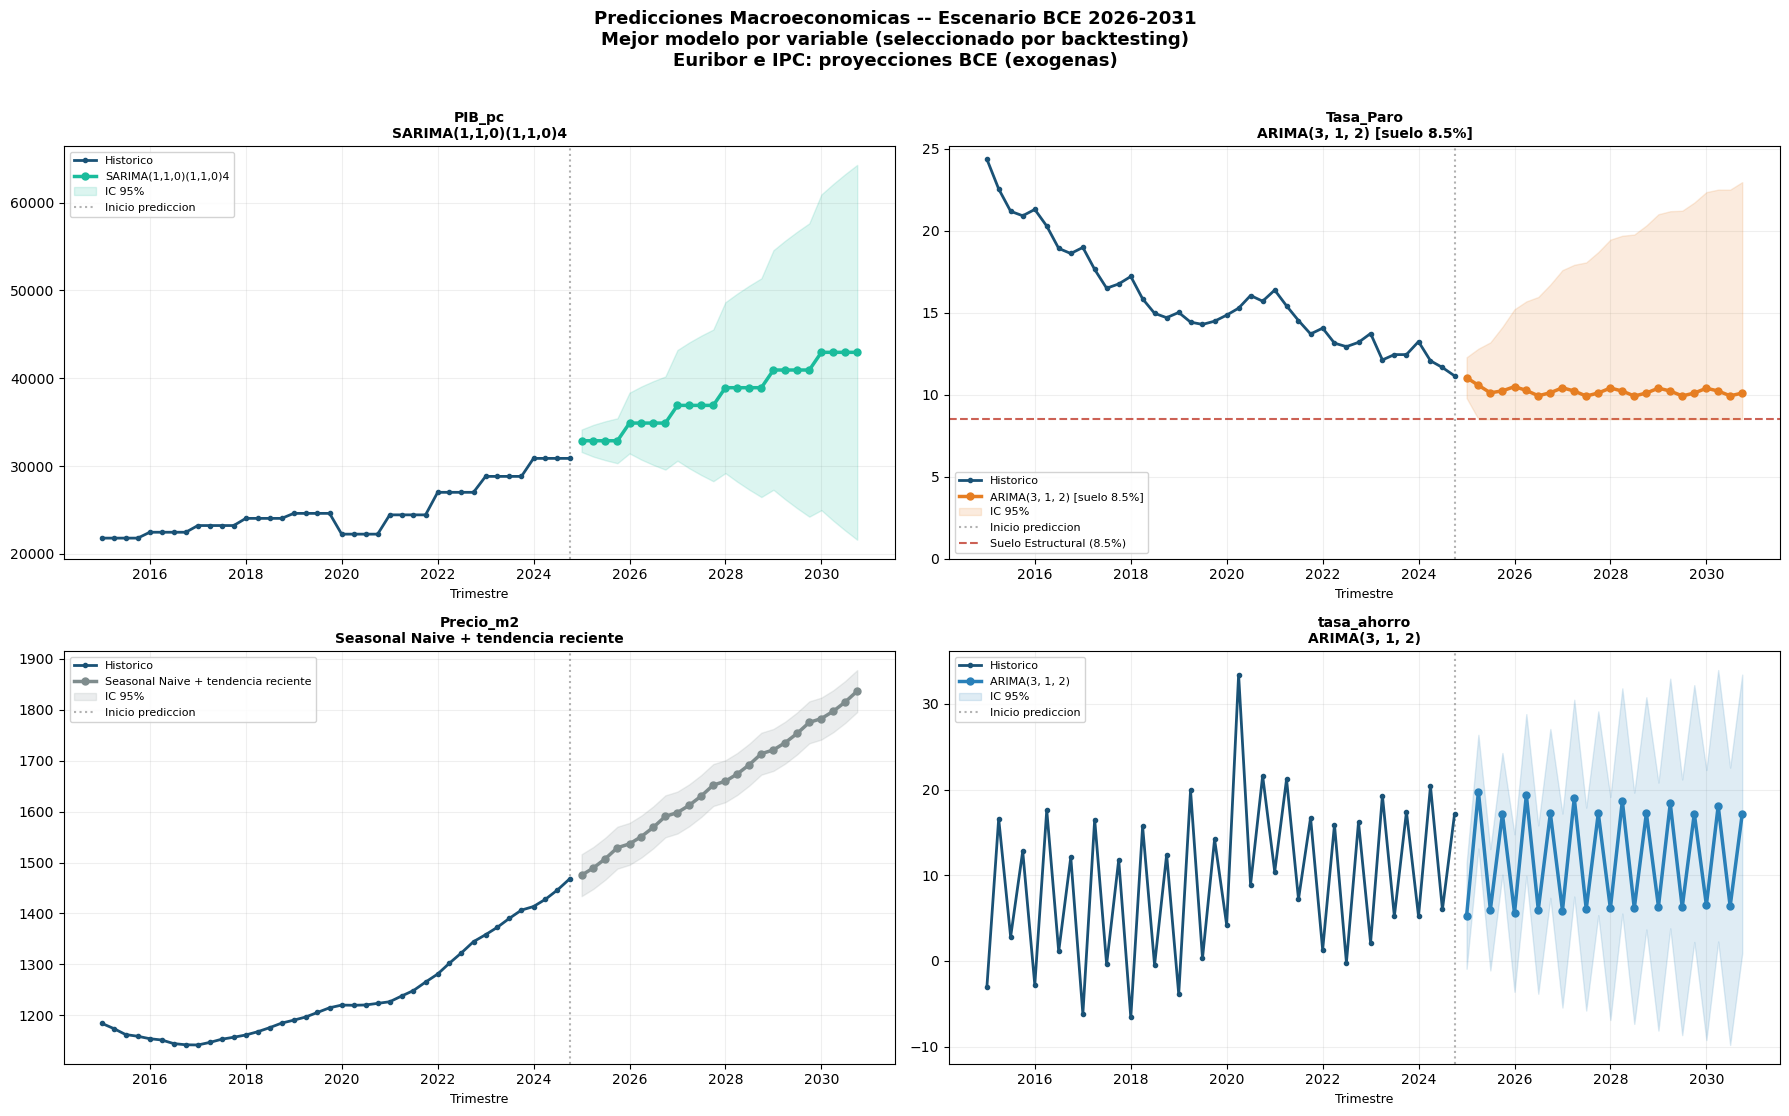

In [ ]:
# ================================================================
#  TFM -- PREDICCION FINAL CON MEJOR MODELO POR VARIABLE
#
#  Ganadores backtesting:
#    PIB_pc       -> SARIMA(1,1,0)(1,1,0)4
#    Tasa_Paro    -> ARIMA (Auto AIC optimizado) + Suelo 8.5%
#    Precio_m2    -> Seasonal Naive + tendencia lineal
#    tasa_ahorro  -> ARIMA (Auto AIC)
#
#  Euribor e IPC: proyecciones oficiales BCE (exogenas, no modelizadas)
#  Horizonte: 24 trimestres (2026Q1 - 2031Q4)  <--- ACTUALIZADO
# ================================================================

import statsmodels.api as sm
from statsmodels.tsa.api import VAR
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# ----------------------------------------------------------------
#  0. CONFIGURACION
# ----------------------------------------------------------------
ALL_COLS = ['PIB_pc', 'Tasa_Paro', 'Precio_m2', 'tasa_ahorro', 'Euribor', 'IPC']
TARGETS  = ['PIB_pc', 'Tasa_Paro', 'Precio_m2', 'tasa_ahorro']
EXOG     = ['Euribor', 'IPC']

# AÑADIDO EL AÑO 2031 PARA LLEGAR A LOS 24 TRIMESTRES
ESCENARIOS_BCE = {
    'Euribor': {'2026': 2.00, '2027': 2.10, '2028': 2.30, '2029': 2.15, '2030': 2.15, '2031': 2.15},
    'IPC':     {'2026': 1.88, '2027': 2.10, '2028': 2.00, '2029': 2.00, '2030': 2.00, '2031': 2.00},
}

def anuales_a_trimestrales(d):
    vals = []
    for anio in sorted(d.keys()):
        vals.extend([d[anio]] * 4)
    return vals

EURIBOR_PROJ = anuales_a_trimestrales(ESCENARIOS_BCE['Euribor'])
IPC_PROJ     = anuales_a_trimestrales(ESCENARIOS_BCE['IPC'])
N_STEPS      = len(EURIBOR_PROJ)  # Ahora esto será automáticamente 24

# ----------------------------------------------------------------
#  1. DATOS
# ----------------------------------------------------------------
df_q = df.copy()
df_q['Trimestre'] = pd.to_datetime(df_q['Trimestre'])
df_nac = df_q.groupby('Trimestre')[ALL_COLS].mean().sort_index()
df_nac.index = pd.DatetimeIndex(df_nac.index)

df_full = df_nac.dropna(subset=TARGETS)
print(f"Muestra completa: {df_full.index[0].date()} -> {df_full.index[-1].date()}  ({len(df_full)} obs)")

last_date  = df_full.index[-1]
future_idx = pd.date_range(start=last_date + pd.DateOffset(months=3),
                            periods=N_STEPS, freq='QS')
print(f"Horizonte pred:   {future_idx[0].date()} -> {future_idx[-1].date()}  ({N_STEPS} trimestres)\n")

# ----------------------------------------------------------------
#  2. PIB_pc -- SARIMA(1,1,0)(1,1,0)4
# ----------------------------------------------------------------
print("-- PIB_pc  ->  SARIMA(1,1,0)(1,1,0)4")
tr_pib = pd.Series(df_full['PIB_pc'].values)
try:
    r_pib    = sm.tsa.SARIMAX(tr_pib, order=(1,1,0),
                               seasonal_order=(1,1,0,4)).fit(disp=False)
    fc_pib   = r_pib.get_forecast(steps=N_STEPS)
    pred_pib = fc_pib.predicted_mean.values
    ci_pib   = fc_pib.conf_int()
    lo_pib   = ci_pib.iloc[:,0].values
    hi_pib   = ci_pib.iloc[:,1].values
    print(f"   OK")
except Exception as e:
    print(f"   ERROR: {e}")
    pred_pib = lo_pib = hi_pib = np.full(N_STEPS, np.nan)

# ----------------------------------------------------------------
#  3. Tasa_Paro -- ARIMA (Auto AIC) con Suelo Estructural
# ----------------------------------------------------------------
print("-- Tasa_Paro  ->  ARIMA (Auto AIC)")
PARO_MIN = 8.5  # Suelo estructural asumiendo factores exógenos ceteris paribus

try:
    tr_paro = pd.Series(df_full['Tasa_Paro'].values)
    
    # Bucle de optimización: Auto-ARIMA para buscar el menor error
    best_aic, best_order_paro, best_res_paro = np.inf, None, None
    for p in range(0, 4):
        for d in range(0, 2):
            for q in range(0, 3):
                try:
                    r = sm.tsa.ARIMA(tr_paro, order=(p, d, q)).fit()
                    if r.aic < best_aic:
                        best_aic, best_order_paro, best_res_paro = r.aic, (p,d,q), r
                except:
                    pass
                    
    print(f"   Mejor orden AIC encontrado: {best_order_paro}  (AIC={best_aic:.1f})")
    
    # Predicción e intervalos
    fc_paro = best_res_paro.get_forecast(steps=N_STEPS)
    pred_paro_raw = fc_paro.predicted_mean.values
    ci_paro = fc_paro.conf_int()
    lo_paro_raw = ci_paro.iloc[:,0].values
    hi_paro_raw = ci_paro.iloc[:,1].values

    # Aplicamos el clip de seguridad (suelo 8.5%)
    pred_paro = np.clip(pred_paro_raw, PARO_MIN, None)
    lo_paro   = np.clip(lo_paro_raw, PARO_MIN, None)
    hi_paro   = hi_paro_raw
    
    print(f"   OK  (Suelo estructural aplicado: {PARO_MIN}%)")

except Exception as e:
    print(f"   ERROR: {e}")
    pred_paro = lo_paro = hi_paro = np.full(N_STEPS, np.nan)
    best_order_paro = "Error"

# ----------------------------------------------------------------
#  4. Precio_m2 -- Seasonal Naive + tendencia lineal reciente
# ----------------------------------------------------------------
print("-- Precio_m2  ->  Seasonal Naive + tendencia reciente")
try:
    tr_pm2    = df_full['Precio_m2'].dropna()
    tendencia = tr_pm2.diff().iloc[-8:].mean()
    print(f"   Tendencia reciente: {tendencia:.2f} EUR/m2 por trimestre")

    base = np.array([tr_pm2.iloc[-(4 - i % 4)] for i in range(N_STEPS)])
    drift = np.array([(i // 4 + 1) * 4 * tendencia for i in range(N_STEPS)])
    pred_pm2 = base + drift

    std_qs = tr_pm2.diff(4).iloc[-16:].std()
    lo_pm2 = pred_pm2 - 1.96 * std_qs
    hi_pm2 = pred_pm2 + 1.96 * std_qs
    print(f"   OK")
except Exception as e:
    print(f"   ERROR: {e}")
    pred_pm2 = lo_pm2 = hi_pm2 = np.full(N_STEPS, np.nan)

# ----------------------------------------------------------------
#  5. tasa_ahorro -- ARIMA (auto AIC)
# ----------------------------------------------------------------
print("-- tasa_ahorro  ->  ARIMA (auto AIC)")
try:
    tr_aho = pd.Series(df_full['tasa_ahorro'].values)
    best_aic, best_order_aho, best_res_aho = np.inf, None, None
    for p in range(0, 4):
        for d in range(0, 2):
            for q in range(0, 3):
                try:
                    r = sm.tsa.ARIMA(tr_aho, order=(p, d, q)).fit()
                    if r.aic < best_aic:
                        best_aic, best_order_aho, best_res_aho = r.aic, (p,d,q), r
                except:
                    pass
    print(f"   Mejor orden AIC encontrado: {best_order_aho}  (AIC={best_aic:.1f})")
    fc_aho   = best_res_aho.get_forecast(steps=N_STEPS)
    pred_aho = fc_aho.predicted_mean.values
    ci_aho   = fc_aho.conf_int()
    lo_aho   = ci_aho.iloc[:,0].values
    hi_aho   = ci_aho.iloc[:,1].values
    print(f"   OK")
except Exception as e:
    print(f"   ERROR: {e}")
    pred_aho = lo_aho = hi_aho = np.full(N_STEPS, np.nan)
    best_order_aho = "Error"

# ----------------------------------------------------------------
#  6. TABLA RESUMEN
# ----------------------------------------------------------------
pred_dict = {
    'PIB_pc':      pred_pib,
    'Tasa_Paro':   pred_paro,
    'Precio_m2':   pred_pm2,
    'tasa_ahorro': pred_aho,
}
lo_dict = {'PIB_pc': lo_pib, 'Tasa_Paro': lo_paro,
           'Precio_m2': lo_pm2, 'tasa_ahorro': lo_aho}
hi_dict = {'PIB_pc': hi_pib, 'Tasa_Paro': hi_paro,
           'Precio_m2': hi_pm2, 'tasa_ahorro': hi_aho}

modelos_ganadores = {
    'PIB_pc':      'SARIMA(1,1,0)(1,1,0)4',
    'Tasa_Paro':   f'ARIMA{best_order_paro} [suelo {PARO_MIN}%]',
    'Precio_m2':   'Seasonal Naive + tendencia reciente',
    'tasa_ahorro': f'ARIMA{best_order_aho}',
}

df_pred = pd.DataFrame({'Trimestre': future_idx})
for var in TARGETS:
    df_pred[var] = pred_dict[var].round(3)

print("\n\n" + "="*72)
print("  PREDICCIONES FINALES -- Escenario BCE 2026-2031")
print(f"  {'Trimestre':<12}", end='')
for var in TARGETS:
    print(f"  {var:>14}", end='')
print()
print("-"*72)
for _, row in df_pred.iterrows():
    print(f"  {str(row['Trimestre'].date()):<12}", end='')
    for var in TARGETS:
        print(f"  {row[var]:>14.2f}", end='')
    print()
print("="*72)
print("\n  Modelos:")
for var, mod in modelos_ganadores.items():
    print(f"    {var:<14} -> {mod}")
print("  Euribor / IPC  -> Proyecciones BCE (exogenas)")
print(f"  Euribor 2026-2031: {list(ESCENARIOS_BCE['Euribor'].values())}")
print(f"  IPC     2026-2031: {list(ESCENARIOS_BCE['IPC'].values())}\n")

# ----------------------------------------------------------------
#  7. GRAFICAS
# ----------------------------------------------------------------
COLORS_PRED = {
    'PIB_pc':      '#1ABC9C',
    'Tasa_Paro':   '#E67E22',
    'Precio_m2':   '#7F8C8D',
    'tasa_ahorro': '#2980B9',
}

fig, axes = plt.subplots(2, 2, figsize=(18, 11))
fig.suptitle(
    'Predicciones Macroeconomicas -- Escenario BCE 2026-2031\n'
    'Mejor modelo por variable (seleccionado por backtesting)\n'
    'Euribor e IPC: proyecciones BCE (exogenas)',
    fontsize=13, fontweight='bold', y=1.01
)
axes = axes.flatten()

for idx, var in enumerate(TARGETS):
    ax     = axes[idx]
    hist   = df_full[var].dropna()
    preds  = pred_dict[var]
    lo     = lo_dict[var]
    hi     = hi_dict[var]
    color  = COLORS_PRED[var]
    modelo = modelos_ganadores[var]

    # Plot del histórico
    hist_plot = hist[hist.index >= '2015-01-01']
    ax.plot(hist_plot.index, hist_plot.values,
            color='#1A5276', linewidth=2, marker='o', markersize=3,
            label='Historico', zorder=3)
            
    # Plot de la predicción
    ax.plot(future_idx, preds,
            color=color, linewidth=2.5, marker='o', markersize=5,
            label=modelo, zorder=5)
            
    # Sombreado del Intervalo de Confianza
    if lo is not None and not np.all(np.isnan(lo)):
        ax.fill_between(future_idx, lo, hi,
                        color=color, alpha=0.15, label='IC 95%', zorder=4)
                        
    # Línea vertical de inicio de predicción
    ax.axvline(x=hist.index[-1], color='gray', linestyle=':', alpha=0.6,
               label='Inicio prediccion')
               
    # -----------------------------------------------------------------
    # AJUSTE VISUAL ESPECÍFICO PARA LA TASA DE PARO
    # -----------------------------------------------------------------
    if var == 'Tasa_Paro':
        ax.set_ylim(bottom=0)  # Obligamos a que el gráfico empiece en 0
        # Dibujamos una línea recta para que el "suelo" sea obvio a la vista
        ax.axhline(y=PARO_MIN, color='#C0392B', linestyle='--', linewidth=1.5, 
                   alpha=0.8, label=f'Suelo Estructural ({PARO_MIN}%)', zorder=2)
    # -----------------------------------------------------------------

    ax.set_title(f'{var}\n{modelo}', fontsize=10, fontweight='bold')
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8, loc='best', framealpha=0.85)
    ax.set_xlabel('Trimestre', fontsize=9)

plt.tight_layout()
plt.show()

Muestra completa: 2005-01-01 -> 2024-10-01  (80 obs)
Horizonte pred:   2025-01-01 -> 2030-10-01  (24 trimestres)

-- PIB_pc  ->  SARIMA(1,1,0)(1,1,0)4
   OK
-- Tasa_Paro  ->  ARIMA (Auto AIC)
   Mejor orden AIC: (3, 1, 2)  (AIC=167.9)
   OK  (Suelo estructural aplicado: 8.5%)
-- Precio_m2  ->  Seasonal Naive + tendencia reciente
   Tendencia reciente: 15.37 EUR/m2 por trimestre
   OK
-- tasa_ahorro  ->  ARIMA (Auto AIC)
   Mejor orden AIC: (3, 1, 2)  (AIC=422.6)
   OK
-- Transmisiones_Total  ->  Seasonal Naive + tendencia (excl. Q4 2025)
   Último dato incluido:  2025-07-01  valor=574,637
   Dato excluido (anóm.): 2025-10-01  valor=398,200  (media histórica=503,959)
   Tendencia interanual reciente: 10,317 transacciones/año
   Rango nacional proyectado: 545,045 – 648,533
   OK


  PREDICCIONES FINALES -- Escenario BCE 2026-2031
  Trimestre                 PIB_pc           Tasa_Paro           Precio_m2         tasa_ahorro  Transmisiones_Total
--------------------------------------------

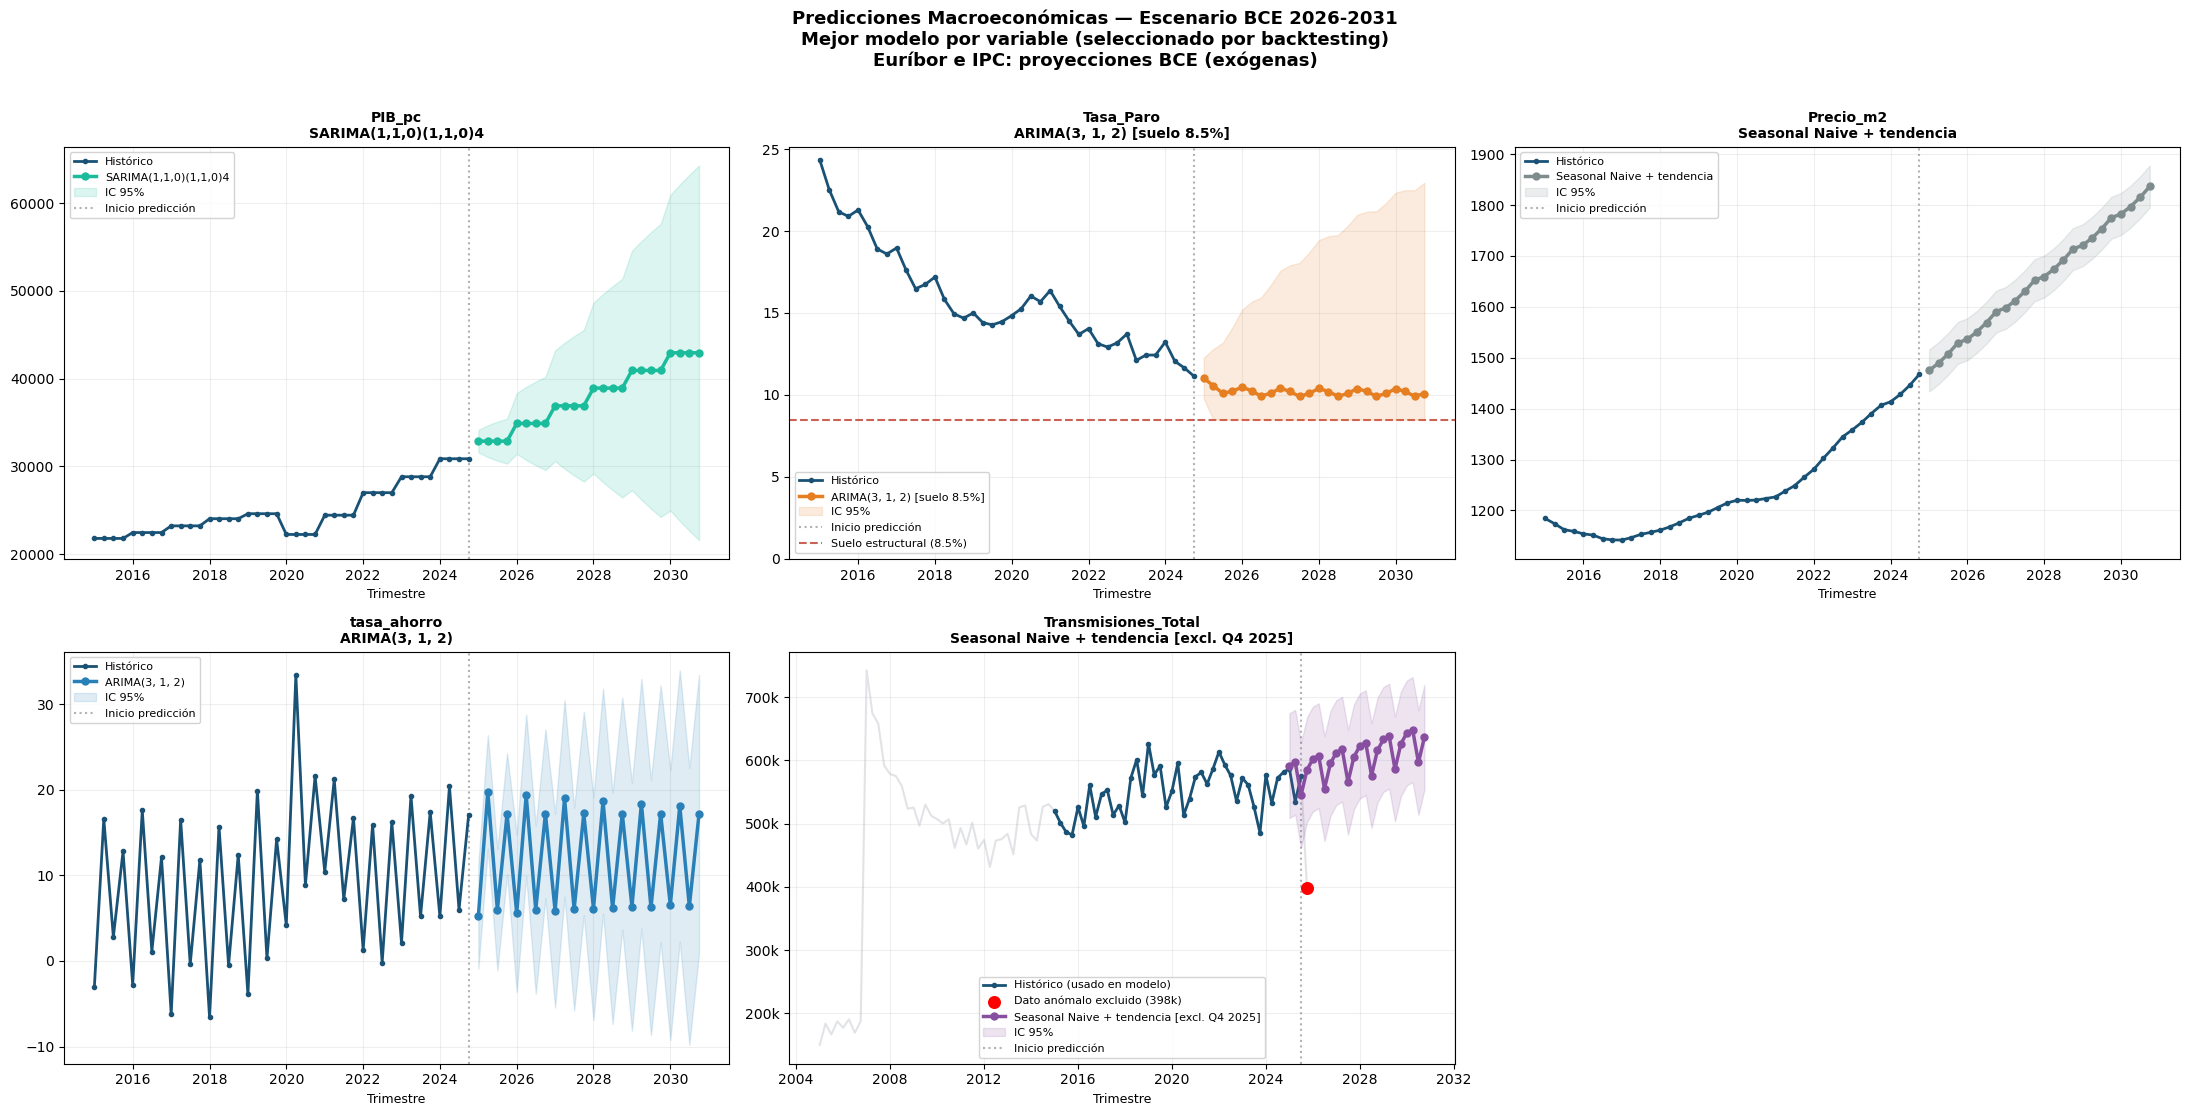


✅ pred_dict listo con las 5 variables proyectadas
   pred_trans_prov disponible para Cell 53 (nacional / 52 provincias)


In [ ]:
# ================================================================
#  TFM -- PREDICCION FINAL CON MEJOR MODELO POR VARIABLE
#
#  Ganadores backtesting:
#    PIB_pc              -> SARIMA(1,1,0)(1,1,0)4
#    Tasa_Paro           -> ARIMA (Auto AIC optimizado) + Suelo 8.5%
#    Precio_m2           -> Seasonal Naive + tendencia lineal
#    tasa_ahorro         -> ARIMA (Auto AIC)
#    Transmisiones_Total -> Seasonal Naive + tendencia (excl. Q4 2025 anómalo)
#
#  Euribor e IPC: proyecciones oficiales BCE (exogenas, no modelizadas)
#  Horizonte: 24 trimestres (2026Q1 - 2031Q4)
# ================================================================

import statsmodels.api as sm
from statsmodels.tsa.api import VAR
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('/Users/fran/Documents/Proyectos máster/TFM/dataset_final_tfm.csv')

# ----------------------------------------------------------------
#  0. CONFIGURACION
# ----------------------------------------------------------------
ALL_COLS = ['PIB_pc', 'Tasa_Paro', 'Precio_m2', 'tasa_ahorro', 'Euribor', 'IPC']
TARGETS  = ['PIB_pc', 'Tasa_Paro', 'Precio_m2', 'tasa_ahorro']
EXOG     = ['Euribor', 'IPC']

ESCENARIOS_BCE = {
    'Euribor': {'2026': 2.00, '2027': 2.10, '2028': 2.30, '2029': 2.15, '2030': 2.15, '2031': 2.15},
    'IPC':     {'2026': 1.88, '2027': 2.10, '2028': 2.00, '2029': 2.00, '2030': 2.00, '2031': 2.00},
}

def anuales_a_trimestrales(d):
    vals = []
    for anio in sorted(d.keys()):
        vals.extend([d[anio]] * 4)
    return vals

EURIBOR_PROJ = anuales_a_trimestrales(ESCENARIOS_BCE['Euribor'])
IPC_PROJ     = anuales_a_trimestrales(ESCENARIOS_BCE['IPC'])
N_STEPS      = len(EURIBOR_PROJ)  # 24 trimestres

# ----------------------------------------------------------------
#  1. DATOS
# ----------------------------------------------------------------
df_q = df.copy()
df_q['Trimestre'] = pd.to_datetime(df_q['Trimestre'])
df_nac = df_q.groupby('Trimestre')[ALL_COLS].mean().sort_index()
df_nac.index = pd.DatetimeIndex(df_nac.index)

df_full = df_nac.dropna(subset=TARGETS)
print(f"Muestra completa: {df_full.index[0].date()} -> {df_full.index[-1].date()}  ({len(df_full)} obs)")

last_date  = df_full.index[-1]
future_idx = pd.date_range(start=last_date + pd.DateOffset(months=3),
                            periods=N_STEPS, freq='QS')
print(f"Horizonte pred:   {future_idx[0].date()} -> {future_idx[-1].date()}  ({N_STEPS} trimestres)\n")

# Transmisiones: agregado nacional
trans_nac = df_q.groupby('Trimestre')['Transmisiones_Total'].sum().sort_index()
trans_nac.index = pd.DatetimeIndex(trans_nac.index)
tr_trans = trans_nac.dropna()

# ----------------------------------------------------------------
#  2. PIB_pc -- SARIMA(1,1,0)(1,1,0)4
# ----------------------------------------------------------------
print("-- PIB_pc  ->  SARIMA(1,1,0)(1,1,0)4")
tr_pib = pd.Series(df_full['PIB_pc'].values)
try:
    r_pib    = sm.tsa.SARIMAX(tr_pib, order=(1,1,0),
                               seasonal_order=(1,1,0,4)).fit(disp=False)
    fc_pib   = r_pib.get_forecast(steps=N_STEPS)
    pred_pib = fc_pib.predicted_mean.values
    ci_pib   = fc_pib.conf_int()
    lo_pib   = ci_pib.iloc[:,0].values
    hi_pib   = ci_pib.iloc[:,1].values
    print(f"   OK")
except Exception as e:
    print(f"   ERROR: {e}")
    pred_pib = lo_pib = hi_pib = np.full(N_STEPS, np.nan)

# ----------------------------------------------------------------
#  3. Tasa_Paro -- ARIMA (Auto AIC) + Suelo estructural
# ----------------------------------------------------------------
print("-- Tasa_Paro  ->  ARIMA (Auto AIC)")
PARO_MIN = 8.5

try:
    tr_paro = pd.Series(df_full['Tasa_Paro'].values)
    best_aic, best_order_paro, best_res_paro = np.inf, None, None
    for p in range(0, 4):
        for d in range(0, 2):
            for q in range(0, 3):
                try:
                    r = sm.tsa.ARIMA(tr_paro, order=(p, d, q)).fit()
                    if r.aic < best_aic:
                        best_aic, best_order_paro, best_res_paro = r.aic, (p,d,q), r
                except:
                    pass
    print(f"   Mejor orden AIC: {best_order_paro}  (AIC={best_aic:.1f})")
    fc_paro       = best_res_paro.get_forecast(steps=N_STEPS)
    pred_paro_raw = fc_paro.predicted_mean.values
    ci_paro       = fc_paro.conf_int()
    lo_paro_raw   = ci_paro.iloc[:,0].values
    hi_paro_raw   = ci_paro.iloc[:,1].values
    pred_paro     = np.clip(pred_paro_raw, PARO_MIN, None)
    lo_paro       = np.clip(lo_paro_raw,   PARO_MIN, None)
    hi_paro       = hi_paro_raw
    print(f"   OK  (Suelo estructural aplicado: {PARO_MIN}%)")
except Exception as e:
    print(f"   ERROR: {e}")
    pred_paro = lo_paro = hi_paro = np.full(N_STEPS, np.nan)
    best_order_paro = "Error"

# ----------------------------------------------------------------
#  4. Precio_m2 -- Seasonal Naive + tendencia lineal reciente
# ----------------------------------------------------------------
print("-- Precio_m2  ->  Seasonal Naive + tendencia reciente")
try:
    tr_pm2    = df_full['Precio_m2'].dropna()
    tendencia = tr_pm2.diff().iloc[-8:].mean()
    print(f"   Tendencia reciente: {tendencia:.2f} EUR/m2 por trimestre")
    base      = np.array([tr_pm2.iloc[-(4 - i % 4)] for i in range(N_STEPS)])
    drift     = np.array([(i // 4 + 1) * 4 * tendencia for i in range(N_STEPS)])
    pred_pm2  = base + drift
    std_qs    = tr_pm2.diff(4).iloc[-16:].std()
    lo_pm2    = pred_pm2 - 1.96 * std_qs
    hi_pm2    = pred_pm2 + 1.96 * std_qs
    print(f"   OK")
except Exception as e:
    print(f"   ERROR: {e}")
    pred_pm2 = lo_pm2 = hi_pm2 = np.full(N_STEPS, np.nan)

# ----------------------------------------------------------------
#  5. tasa_ahorro -- ARIMA (Auto AIC)
# ----------------------------------------------------------------
print("-- tasa_ahorro  ->  ARIMA (Auto AIC)")
try:
    tr_aho = pd.Series(df_full['tasa_ahorro'].values)
    best_aic, best_order_aho, best_res_aho = np.inf, None, None
    for p in range(0, 4):
        for d in range(0, 2):
            for q in range(0, 3):
                try:
                    r = sm.tsa.ARIMA(tr_aho, order=(p, d, q)).fit()
                    if r.aic < best_aic:
                        best_aic, best_order_aho, best_res_aho = r.aic, (p,d,q), r
                except:
                    pass
    print(f"   Mejor orden AIC: {best_order_aho}  (AIC={best_aic:.1f})")
    fc_aho   = best_res_aho.get_forecast(steps=N_STEPS)
    pred_aho = fc_aho.predicted_mean.values
    ci_aho   = fc_aho.conf_int()
    lo_aho   = ci_aho.iloc[:,0].values
    hi_aho   = ci_aho.iloc[:,1].values
    print(f"   OK")
except Exception as e:
    print(f"   ERROR: {e}")
    pred_aho = lo_aho = hi_aho = np.full(N_STEPS, np.nan)
    best_order_aho = "Error"

# ----------------------------------------------------------------
#  6. Transmisiones_Total -- Seasonal Naive + tendencia
#     Q4 2025 es un dato anómalo (398k vs media ~550k) que
#     distorsiona cualquier modelo ARIMA/SARIMA. Se entrena
#     hasta Q3 2025 excluyendo ese último valor.
# ----------------------------------------------------------------
print("-- Transmisiones_Total  ->  Seasonal Naive + tendencia (excl. Q4 2025)")
try:
    tr_trans_clean = tr_trans.iloc[:-1]
    print(f"   Último dato incluido:  {tr_trans_clean.index[-1].date()}  "
          f"valor={tr_trans_clean.iloc[-1]:,.0f}")
    print(f"   Dato excluido (anóm.): {tr_trans.index[-1].date()}  "
          f"valor={tr_trans.iloc[-1]:,.0f}  "
          f"(media histórica={tr_trans.iloc[:-1].mean():,.0f})")

    tendencia_trans = tr_trans_clean.diff(4).iloc[-8:].mean()
    print(f"   Tendencia interanual reciente: {tendencia_trans:,.0f} transacciones/año")

    base_trans     = np.array([float(tr_trans_clean.iloc[-(4 - i % 4)])
                                for i in range(N_STEPS)])
    drift_trans    = np.array([(i // 4 + 1) * tendencia_trans
                                for i in range(N_STEPS)])
    pred_trans_nac = base_trans + drift_trans
    std_trans      = tr_trans_clean.diff(4).iloc[-16:].std()
    lo_trans       = np.clip(pred_trans_nac - 1.96 * std_trans, 0, None)
    hi_trans       = pred_trans_nac + 1.96 * std_trans
    pred_trans_prov = pred_trans_nac / 52
    print(f"   Rango nacional proyectado: {pred_trans_nac.min():,.0f} – "
          f"{pred_trans_nac.max():,.0f}")
    print(f"   OK")
except Exception as e:
    print(f"   ERROR: {e}")
    pred_trans_nac  = np.full(N_STEPS, float(tr_trans.iloc[-5:-1].mean()))
    pred_trans_prov = pred_trans_nac / 52
    lo_trans        = pred_trans_nac * 0.90
    hi_trans        = pred_trans_nac * 1.10

# ----------------------------------------------------------------
#  7. EMPAQUETADO
# ----------------------------------------------------------------
pred_dict = {
    'PIB_pc':              pred_pib,
    'Tasa_Paro':           pred_paro,
    'Precio_m2':           pred_pm2,
    'tasa_ahorro':         pred_aho,
    'Transmisiones_Total': pred_trans_nac,
}
lo_dict = {
    'PIB_pc':              lo_pib,
    'Tasa_Paro':           lo_paro,
    'Precio_m2':           lo_pm2,
    'tasa_ahorro':         lo_aho,
    'Transmisiones_Total': lo_trans,
}
hi_dict = {
    'PIB_pc':              hi_pib,
    'Tasa_Paro':           hi_paro,
    'Precio_m2':           hi_pm2,
    'tasa_ahorro':         hi_aho,
    'Transmisiones_Total': hi_trans,
}
modelos_ganadores = {
    'PIB_pc':              'SARIMA(1,1,0)(1,1,0)4',
    'Tasa_Paro':           f'ARIMA{best_order_paro} [suelo {PARO_MIN}%]',
    'Precio_m2':           'Seasonal Naive + tendencia',
    'tasa_ahorro':         f'ARIMA{best_order_aho}',
    'Transmisiones_Total': 'Seasonal Naive + tendencia [excl. Q4 2025]',
}

ALL_VARS_PRED = TARGETS + ['Transmisiones_Total']
df_pred = pd.DataFrame({'Trimestre': future_idx})
for var in ALL_VARS_PRED:
    df_pred[var] = pred_dict[var].round(2)

# ----------------------------------------------------------------
#  8. TABLA RESUMEN
# ----------------------------------------------------------------
print("\n\n" + "="*95)
print("  PREDICCIONES FINALES -- Escenario BCE 2026-2031")
print(f"  {'Trimestre':<12}", end='')
for var in ALL_VARS_PRED:
    print(f"  {var:>18}", end='')
print()
print("-"*95)
for _, row in df_pred.iterrows():
    print(f"  {str(row['Trimestre'].date()):<12}", end='')
    for var in ALL_VARS_PRED:
        print(f"  {row[var]:>18.2f}", end='')
    print()
print("="*95)
print("\n  Modelos:")
for var, mod in modelos_ganadores.items():
    print(f"    {var:<22} -> {mod}")
print("  Euribor / IPC  -> Proyecciones BCE (exogenas)")
print(f"  Euribor 2026-2031: {list(ESCENARIOS_BCE['Euribor'].values())}")
print(f"  IPC     2026-2031: {list(ESCENARIOS_BCE['IPC'].values())}\n")

# ----------------------------------------------------------------
#  9. GRAFICAS (2x3 — 5 variables + celda vacía)
# ----------------------------------------------------------------
COLORS_PRED = {
    'PIB_pc':              '#1ABC9C',
    'Tasa_Paro':           '#E67E22',
    'Precio_m2':           '#7F8C8D',
    'tasa_ahorro':         '#2980B9',
    'Transmisiones_Total': '#884EA0',
}

fig, axes = plt.subplots(2, 3, figsize=(22, 11))
fig.suptitle(
    'Predicciones Macroeconómicas — Escenario BCE 2026-2031\n'
    'Mejor modelo por variable (seleccionado por backtesting)\n'
    'Euríbor e IPC: proyecciones BCE (exógenas)',
    fontsize=13, fontweight='bold', y=1.01
)
axes_flat = axes.flatten()

for idx, var in enumerate(ALL_VARS_PRED):
    ax    = axes_flat[idx]
    color = COLORS_PRED[var]
    modelo = modelos_ganadores[var]
    preds  = pred_dict[var]
    lo     = lo_dict[var]
    hi     = hi_dict[var]

    # ── Plot especial para Transmisiones ─────────────────────────
    if var == 'Transmisiones_Total':
        # Serie completa en gris (incluye Q4 2025 anómalo)
        ax.plot(tr_trans.index, tr_trans.values,
                color='#D5D8DC', linewidth=1.5, alpha=0.7, zorder=1)
        # Serie limpia en azul (excluye Q4 2025)
        hist_clean_plot = tr_trans_clean[tr_trans_clean.index >= '2015-01-01']
        ax.plot(hist_clean_plot.index, hist_clean_plot.values,
                color='#1A5276', linewidth=2, marker='o', markersize=3,
                label='Histórico (usado en modelo)', zorder=3)
        # Marcar dato anómalo excluido
        ax.scatter([tr_trans.index[-1]], [tr_trans.iloc[-1]],
                   color='red', s=70, zorder=6,
                   label=f'Dato anómalo excluido ({tr_trans.iloc[-1]/1000:.0f}k)')
        # Predicción
        ax.plot(future_idx, preds,
                color=color, linewidth=2.5, marker='o', markersize=5,
                label=modelo, zorder=5)
        ax.fill_between(future_idx, lo, hi,
                        color=color, alpha=0.15, label='IC 95%', zorder=4)
        ax.axvline(x=tr_trans_clean.index[-1], color='gray',
                   linestyle=':', alpha=0.6, label='Inicio predicción')
        ax.yaxis.set_major_formatter(
            plt.FuncFormatter(lambda x, _: f'{int(x/1000)}k'))

    # ── Plot genérico para el resto de variables ──────────────────
    else:
        hist      = df_full[var].dropna()
        hist_plot = hist[hist.index >= '2015-01-01']
        ax.plot(hist_plot.index, hist_plot.values,
                color='#1A5276', linewidth=2, marker='o', markersize=3,
                label='Histórico', zorder=3)
        ax.plot(future_idx, preds,
                color=color, linewidth=2.5, marker='o', markersize=5,
                label=modelo, zorder=5)
        if lo is not None and not np.all(np.isnan(lo)):
            ax.fill_between(future_idx, lo, hi,
                            color=color, alpha=0.15, label='IC 95%', zorder=4)
        ax.axvline(x=hist.index[-1], color='gray',
                   linestyle=':', alpha=0.6, label='Inicio predicción')
        if var == 'Tasa_Paro':
            ax.set_ylim(bottom=0)
            ax.axhline(y=PARO_MIN, color='#C0392B', linestyle='--',
                       linewidth=1.5, alpha=0.8,
                       label=f'Suelo estructural ({PARO_MIN}%)', zorder=2)

    ax.set_title(f'{var}\n{modelo}', fontsize=10, fontweight='bold')
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8, loc='best', framealpha=0.85)
    ax.set_xlabel('Trimestre', fontsize=9)

# Ocultar celda vacía
axes_flat[5].set_visible(False)

plt.tight_layout()
plt.show()

print("\n✅ pred_dict listo con las 5 variables proyectadas")
print(f"   pred_trans_prov disponible para Cell 53 (nacional / 52 provincias)")

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings('ignore')
from sklearn.ensemble import RandomForestRegressor

# ══════════════════════════════════════════════════════════════════════════════
# 1. CONSTRUIR TABLA MACRO TRIMESTRAL 2026-2030
# ══════════════════════════════════════════════════════════════════════════════
future_dates_30 = pd.date_range(start='2026-01-01', end='2030-12-31', freq='QS')
N_30 = len(future_dates_30)  # 20

def anuales_a_trimestrales_serie(d, fechas):
    anios = sorted(d.keys())
    serie_anual = pd.Series({pd.Timestamp(f'{a}-01-01'): d[a] for a in anios})
    ultimo = serie_anual.iloc[-1]
    extra  = pd.Series({pd.Timestamp(f'{int(anios[-1])+1}-01-01'): ultimo})
    serie_ext  = pd.concat([serie_anual, extra])
    serie_trim = serie_ext.resample('QS').interpolate(method='linear')
    return serie_trim.reindex(fechas)

df_macro = pd.DataFrame(index=future_dates_30)
df_macro.index.name = 'Trimestre'

# Euribor e IPC: interpolación lineal desde escenarios BCE
df_macro['Euribor'] = anuales_a_trimestrales_serie(
    {int(k): v for k, v in ESCENARIOS_BCE['Euribor'].items()}, future_dates_30)
df_macro['IPC'] = anuales_a_trimestrales_serie(
    {int(k): v for k, v in ESCENARIOS_BCE['IPC'].items()}, future_dates_30)

# Resto de variables macro: primeros 20 pasos de pred_dict
for var in ['PIB_pc', 'Tasa_Paro', 'Precio_m2', 'tasa_ahorro']:
    df_macro[var] = pred_dict[var][:N_30]

# Transmisiones_Total: pred_dict nacional → nivel provincial medio
# Se usa con lag1 en el RF → el trimestre t recibe el valor proyectado de t-1
# (no hay data leakage: cuando predecimos t, ya conocemos la proyección de t-1)
df_macro['Transmisiones_Total'] = pred_trans_nac[:N_30]

print("Escenarios macro trimestrales 2026-2030:")
print(df_macro.round(2).to_string())

# ══════════════════════════════════════════════════════════════════════════════
# 2. RE-ENTRENAMIENTO RF CON TODOS LOS DATOS (2006-2025)
# ══════════════════════════════════════════════════════════════════════════════
df_full = _DF_BASE.copy()

rf_final = RandomForestRegressor(n_estimators=200, max_depth=15,
                                  min_samples_leaf=3, random_state=42)
rf_final.fit(df_full[_FEATURES_CON], df_full['Hipotecas_Total'])
print(f"\nModelo re-entrenado con {len(df_full):,} obs "
      f"({df_full['Trimestre'].nunique()} trim × {df_full['Provincia'].nunique()} provincias)")

# ══════════════════════════════════════════════════════════════════════════════
# 3. PROCESO AUTOREGRESIVO RECURSIVO
# ══════════════════════════════════════════════════════════════════════════════
current = (df_full.sort_values('Trimestre')
                  .groupby('Provincia').tail(1)
                  .copy().reset_index(drop=True))

precio_base_prov   = current['Precio_m2_lag1'].copy().values
precio_base_nac_q1 = df_macro['Precio_m2'].iloc[0]
trans_base_prov    = current['Transmisiones_Total_lag1'].copy().values

historial_lag   = []
preds_nac       = []
preds_prov_list = []  # ← NUEVO

for i, date in enumerate(future_dates_30):
    macro   = df_macro.loc[date]
    current = current.copy()

    current['Euribor']          = macro['Euribor']
    current['IPC_lag1']         = macro['IPC']
    current['Tasa_Paro_lag1']   = macro['Tasa_Paro']
    current['PIB_pc_lag1']      = macro['PIB_pc']
    current['tasa_ahorro_lag1'] = macro['tasa_ahorro']

    ratio = macro['Precio_m2'] / precio_base_nac_q1
    current['Precio_m2_lag1'] = precio_base_prov * ratio

    if i == 0:
        current['Transmisiones_Total_lag1'] = trans_base_prov
    else:
        trans_t_minus_1 = df_macro['Transmisiones_Total'].iloc[i - 1] / 52
        current['Transmisiones_Total_lag1'] = trans_t_minus_1

    preds_prov = rf_final.predict(current[_FEATURES_CON])
    preds_nac.append({'fecha': date, 'hipotecas': preds_prov.sum()})
    historial_lag.append(preds_prov.copy())

    # ── NUEVO: guardar detalle provincial por trimestre ───────────────────
    for prov, val in zip(current['Provincia'], preds_prov):
        preds_prov_list.append({
            'Provincia':  prov,
            'Trimestre':  date.strftime('%Y-Q%q') if hasattr(date, 'quarter') 
                          else f"{date.year}-Q{(date.month-1)//3+1}",
            'hipotecas':  round(val)
        })

    current['Hipotecas_Total_lag1'] = preds_prov
    if i >= 3:
        current['Hipotecas_Total_lag4'] = historial_lag[i - 3]

forecast = pd.DataFrame(preds_nac).set_index('fecha')

# ══════════════════════════════════════════════════════════════════════════════
# 4. RESULTADOS ANUALIZADOS — NACIONAL
# ══════════════════════════════════════════════════════════════════════════════
forecast_anual = forecast['hipotecas'].resample('YE').sum()
hist_anual     = df_full.groupby(df_full['Trimestre'].dt.year)['Hipotecas_Total'].sum()

print("\n═══ PROYECCIÓN ANUAL DE HIPOTECAS — ESPAÑA 2026-2030 ═══")
print(f"{'Año':<8} {'Hipotecas':>14} {'Δ vs ant.':>10} {'Euríbor':>10} "
      f"{'Paro':>8} {'PIB_pc':>10} {'Precio_m2':>11} {'Transmis.':>12}")
print("─" * 85)
prev = hist_anual.iloc[-1]
for year, val in forecast_anual.items():
    yr   = year.year
    chg  = (val / prev - 1) * 100
    eur  = ESCENARIOS_BCE['Euribor'].get(str(yr), 2.15)
    paro = float(df_macro[df_macro.index.year == yr]['Tasa_Paro'].mean())
    pib  = float(df_macro[df_macro.index.year == yr]['PIB_pc'].mean())
    pm2  = float(df_macro[df_macro.index.year == yr]['Precio_m2'].mean())
    tra  = float(df_macro[df_macro.index.year == yr]['Transmisiones_Total'].mean())
    print(f"{yr:<8} {int(val):>14,} {chg:>+9.1f}%  {eur:>9.2f}%  "
          f"{paro:>7.1f}%  {pib:>9.0f}  {pm2:>10.0f}  {tra:>11.0f}")
    prev = val

print(f"\n  Referencia histórica:")
for yr, val in hist_anual.tail(5).items():
    print(f"  {yr}: {int(val):,} hipotecas")

# ══════════════════════════════════════════════════════════════════════════════
# 4b. TABLA PROVINCIAL POR TRIMESTRE  ← NUEVO
# ══════════════════════════════════════════════════════════════════════════════
df_prov = pd.DataFrame(preds_prov_list)

tabla_trim_prov = (
    df_prov
    .groupby(['Provincia', 'Trimestre'])['hipotecas']
    .sum()
    .unstack('Trimestre')
)

# Columna TOTAL y ordenar por demanda total descendente
tabla_trim_prov['TOTAL'] = tabla_trim_prov.sum(axis=1)
tabla_trim_prov = tabla_trim_prov.sort_values('TOTAL', ascending=False)

# Fila de totales nacionales
fila_total = tabla_trim_prov.sum().rename('── ESPAÑA TOTAL ──')
tabla_trim_prov = pd.concat([tabla_trim_prov, fila_total.to_frame().T])

print("\n═══ PROYECCIÓN TRIMESTRAL DE HIPOTECAS POR PROVINCIA 2026-2030 ═══")
print(tabla_trim_prov.to_string(
    formatter={col: '{:,.0f}'.format for col in tabla_trim_prov.columns}
))

print(f"\n  Referencia histórica:")
for yr, val in hist_anual.tail(5).items():
    print(f"  {yr}: {int(val):,} hipotecas")

# ══════════════════════════════════════════════════════════════════════════════
# 5. VISUALIZACIÓN
# ══════════════════════════════════════════════════════════════════════════════
hist_trim = df_full.groupby('Trimestre')['Hipotecas_Total'].sum().sort_index()
eur_hist  = df_full.groupby('Trimestre')['Euribor'].mean().sort_index()

fig, axes = plt.subplots(3, 1, figsize=(15, 14),
                          gridspec_kw={'height_ratios': [2.5, 1, 1]})
fig.suptitle(
    'Demanda Hipotecaria en España — Histórico y Proyección 2026-2030\n'
    'Random Forest Provincial · Macro dinámica: SARIMA/ARIMA/Naive + BCE/FMI',
    fontsize=14, fontweight='bold'
)

# ── Panel 1: hipotecas trimestrales ──────────────────────────────────────
ax1 = axes[0]
ax1.plot(hist_trim.index, hist_trim.values,
         color='#1A1A2E', linewidth=2, label='Histórico (real)', zorder=3)
ax1.plot([hist_trim.index[-1], forecast.index[0]],
         [hist_trim.values[-1], forecast['hipotecas'].values[0]],
         color='#E60000', linewidth=2, linestyle='--', zorder=3)
ax1.plot(forecast.index, forecast['hipotecas'],
         color='#E60000', linewidth=2.5, linestyle='--',
         marker='o', markersize=4, label='Proyección RF 2026-2030', zorder=3)
ax1.axvline(x=hist_trim.index[-1], color='grey',
            linestyle=':', linewidth=1.5, alpha=0.8)
ax1.axvspan(forecast.index[0], forecast.index[-1],
            color='#E60000', alpha=0.06, label='Zona de proyección')
fc_vals = forecast['hipotecas'].values
ax1.fill_between(forecast.index, fc_vals * 0.80, fc_vals * 1.20,
                 color='#E60000', alpha=0.07, label='Banda ±20%')
ax1.fill_between(forecast.index, fc_vals * 0.90, fc_vals * 1.10,
                 color='#E60000', alpha=0.10, label='Banda ±10%')

hitos = {
    '2008\nCrisis':          pd.Timestamp('2008-01-01'),
    '2013\nSuelo':           pd.Timestamp('2013-01-01'),
    '2022\nSubida\nEuríbor': pd.Timestamp('2022-07-01'),
}
for label, fecha in hitos.items():
    if fecha in hist_trim.index:
        val = hist_trim[fecha]
        ax1.annotate(label, xy=(fecha, val), xytext=(fecha, val * 1.25),
                     arrowprops=dict(arrowstyle='->', color='#555'),
                     fontsize=8, color='#333', ha='center')

ax1.set_ylabel('Hipotecas / Trimestre', fontsize=11)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax1.legend(loc='upper right', fontsize=9)
ax1.grid(alpha=0.3)
ax1.tick_params(axis='x', rotation=30)

# ── Panel 2: barras anuales ───────────────────────────────────────────────
ax2 = axes[1]
hist_plot = hist_anual[hist_anual.index >= 2010]
ax2.bar(hist_plot.index, hist_plot.values,
        color='#1A1A2E', alpha=0.75, width=0.6,
        label='Histórico anual', zorder=2)
ax2.bar([y.year for y in forecast_anual.index], forecast_anual.values,
        color='#E60000', alpha=0.65, width=0.6,
        label='Proyección anual', zorder=2)
ax2.set_ylabel('Hipotecas / Año', fontsize=10)
ax2.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{int(x/1000):.0f}k'))
ax2.legend(fontsize=9)
ax2.grid(axis='y', alpha=0.3)
for year, val in forecast_anual.items():
    ax2.text(year.year, val + 6000, f'{int(val/1000)}k',
             ha='center', fontsize=8, color='#E60000', fontweight='bold')

# ── Panel 3: Euríbor histórico + proyectado ───────────────────────────────
ax3 = axes[2]
ax3.plot(eur_hist.index, eur_hist.values,
         color='#1A1A2E', linewidth=1.8, label='Euríbor histórico')
ax3.plot(df_macro.index, df_macro['Euribor'],
         color='#E60000', linewidth=2, linestyle='--',
         marker='o', markersize=3, label='Euríbor BCE (escenario)')
ax3.axvline(x=hist_trim.index[-1], color='grey',
            linestyle=':', linewidth=1.5, alpha=0.8)
ax3.axhline(y=0, color='black', linewidth=0.5, alpha=0.3)
ax3.set_ylabel('Euríbor (%)', fontsize=10)
ax3.legend(fontsize=9)
ax3.grid(alpha=0.3)
ax3.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

print("\n✅ Proyección completada.")
print("   Variables dinámicas: Euríbor (BCE), IPC (BCE), Tasa_Paro (ARIMA),")
print("                        PIB_pc (SARIMA), Precio_m2 (Naive+tendencia),")
print("                        tasa_ahorro (ARIMA), Transmisiones (Seasonal Naive)")
print("   Variables ceteris paribus: demografía, índices de construcción")
print("   Sin data leakage: todas las variables macro entran con lag_1")
print("                     excepto Euríbor (dato oficial en tiempo real)")

Escenarios macro trimestrales 2026-2030:
            Euribor   IPC    PIB_pc  Tasa_Paro  Precio_m2  tasa_ahorro  Transmisiones_Total
Trimestre                                                                                  
2026-01-01     2.00  1.88  32886.49      11.03    1475.06         5.23            591742.12
2026-04-01     2.02  1.94  32886.49      10.56    1489.39        19.75            596947.12
2026-07-01     2.05  1.99  32886.49      10.10    1507.52         5.96            545045.12
2026-10-01     2.08  2.04  32886.49      10.22    1529.11        17.17            584954.12
2027-01-01     2.10  2.10  34901.64      10.48    1536.55         5.58            602059.25
2027-04-01     2.15  2.08  34901.64      10.25    1550.87        19.36            607264.25
2027-07-01     2.20  2.05  34901.64       9.92    1569.01         5.98            555362.25
2027-10-01     2.25  2.02  34901.64      10.11    1590.60        17.21            595271.25
2028-01-01     2.30  2.00  36915.27    

NameError: name '_DF_BASE' is not defined

### Proyección 2026-2030 con el Mejor Modelo

Para simular la demanda hipotecaria hasta diciembre de 2030, utilizaremos un **proceso generativo autoregresivo** a nivel provincial:
1. Tomamos el último trimestre de 2025 de las variables independientes.
2. Para cada trimestre futuro (Q1 2026 - Q4 2030), predecimos el número de hipotecas de cada provincia.
3. El número de hipotecas predicho se convierte en la variable `Hipotecas_Total_lag1` del trimestre siguiente.
4. Agregamos las predicciones provinciales a un total nacional para obtener la curva final.